In [1]:
import os, glob, json, random
from collections import defaultdict, Counter
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from astropy.io import fits
from astropy.time import Time
from astropy.stats import sigma_clipped_stats


classical_night_arcs_dir = "/Users/ani/local/data/soar/slit_test/classical_night_arcs"
aeon_night_arcs_dir = "/Users/ani/local/data/soar/slit_test/aeon_night_arcs"

classical_night_arcs_files = glob.glob(os.path.join(classical_night_arcs_dir, '*.fits'))
aeon_night_arcs_files = glob.glob(os.path.join(aeon_night_arcs_dir, '*.fits*'))  # AEON files are .fits.fz

# Part 1 analyses the classical night
arcs = classical_night_arcs_files

In [2]:
# Global figure style: large fonts, thick lines, big markers, readable dates.
# Multi-panel figures below are stacked vertically so each panel keeps the full width.
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 20,
    "axes.titlesize": 22,
    "axes.titleweight": "bold",
    "axes.labelsize": 20,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.5,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "legend.fontsize": 16,
    "legend.framealpha": 0.9,
    "lines.linewidth": 2.5,
    "lines.markersize": 8,
    "patch.linewidth": 1.5,
    "date.converter": "concise",
})


In [3]:
def read_fits_file(file: str) -> tuple:
    """
    Reads a FITS file and returns a merged header and data dictionary.
    - header: merged across all HDUs (later HDUs overwrite earlier ones on duplicate keys)
    - data: dict of {hdu_index: data_array} for all HDUs
    """
    with fits.open(file) as hdul:
        header = hdul[0].header.copy()  # copy so updates don't mutate the file's primary header
        for i in range(1, len(hdul)):
            header.update(hdul[i].header)
        data = {i: hdul[i].data.copy() if hdul[i].data is not None else None
                for i in range(len(hdul))}  # copy: memmapped data is invalid after the file closes
    return header, data

    
def find_lamp_type(header: dict) -> str:

    # From the file headers, these are all the lamps available.
    lamp_mapping = {
        "LAMP_HGA": "HgAr",
        "LAMP_NE": "Ne",
        "LAMP_AR": "Ar",
        "LAMP_FE": "Fe",
        "LAMP_CU": "Cu",
        "LAMP_QUA": "Quartz",
    }

    # the heaker key hwere the value is True, is the lamp turned on. So I am considering only those lamps that are turned on, and making a tuple of their names. This step is added to identify what was the lamp that was used for the arc.
    Lamps = tuple(
        name 
        for kw, name in lamp_mapping.items() 
        if str(header.get(kw, "")).strip().upper() in ("TRUE", "T")
    )

    # if multple lamps are on, join them with a +, for example: HgAr+Ne
    lamp_str = "+".join(Lamps) if Lamps else "Unknown"

    return lamp_str

In [4]:
# Filter on the specific header keywords instead of scanning every header value.
# Scanning all values also matched OBJECT (science) frames taken in 400_M1, which are not arcs.
# fits.getheader only reads the primary header, so this is much faster than fits.open + loop.
WAVMODE = "400_M1"

rows = []
for arc in arcs:
    h = fits.getheader(arc)
    rows.append({
        "file":     arc,
        "obstype":  str(h.get("OBSTYPE", "")).strip().upper(),
        "wavmode":  str(h.get("WAVMODE", "")).strip().upper().replace("400M1", "400_M1"),
        "lamp":     find_lamp_type(h),
        "slit":     h.get("SLIT"),
        "date_obs": h.get("DATE-OBS"),
        "exptime":  h.get("EXPTIME"),
        "cam_targ": h.get("CAM_TARG"),
        "grt_targ": h.get("GRT_TARG"),
        "posangle": h.get("POSANGLE"),
        "rotator":  h.get("ROTATOR"),
    })

df = pd.DataFrame(rows)
df["date_obs"] = pd.to_datetime(df["date_obs"], errors="coerce")
df = df.sort_values("date_obs").reset_index(drop=True)

good = df[(df["obstype"] == "COMP") & (df["wavmode"] == WAVMODE)]
good_arcs = good["file"].tolist()

print(f"{len(good_arcs)} of {len(arcs)} files are {WAVMODE} COMP arcs")
print(good["lamp"].value_counts())


115 of 122 files are 400_M1 COMP arcs
lamp
HgAr+Ne    115
Name: count, dtype: int64


## 1D arc spectra

Each arc is collapsed to 1D by trimming the overscan (using the `TRIMSEC` header keyword, so it isn't hardcoded) and taking the **median** along the spatial axis. The median is less sensitive to cosmic rays and hot columns than the sum.

Before cross-correlating, the slowly varying continuum is removed with a wide median filter and each spectrum is normalised. This way the correlation is driven by the line positions, not by overall brightness or lamp warm-up.

In [5]:
from scipy.signal import correlate, correlation_lags, medfilt
from scipy.stats import skew, skewtest

def parse_section(sec: str):
    """Convert a FITS section string '[x1:x2,y1:y2]' (1-based, inclusive) to numpy slices."""
    x, y = sec.strip("[]").split(",")
    x1, x2 = map(int, x.split(":"))
    y1, y2 = map(int, y.split(":"))
    return slice(y1 - 1, y2), slice(x1 - 1, x2)


def extract_1d_arc_spectrum(filepath: str) -> np.ndarray:
    header, data = read_fits_file(filepath)
    image = next(d for d in data.values() if d is not None and d.ndim == 2)
    ys, xs = parse_section(header.get("TRIMSEC", f"[1:{image.shape[1]},1:{image.shape[0]}]"))
    return np.median(image[ys, xs], axis=0).astype(np.float64)


def prepare_for_xcorr(spec: np.ndarray, kernel: int = 101) -> np.ndarray:
    """Subtract a smooth continuum and normalise to unit variance."""
    s = spec - medfilt(spec, kernel)
    return (s - s.mean()) / s.std()


spectra = {f: extract_1d_arc_spectrum(f) for f in good_arcs}
print(f"Extracted {len(spectra)} spectra, length {len(next(iter(spectra.values())))} px")


Extracted 115 spectra, length 2030 px


## Cross-correlation against the first arc

The reference is the **earliest** arc. `good_arcs` is sorted by `DATE-OBS`, so this is the first exposure, not whichever file `glob` happened to return first. The reference is left out of the results (its autocorrelation always gives 0 shift).

The plain `argmax` of the correlation only gives whole-pixel shifts. Mask-cycling offsets are likely around one pixel, so the peak is refined by fitting a parabola through the three highest points, which gives a sub-pixel shift.

**Sign convention:** positive `dx` means the lines in that arc sit at *higher* pixel values than in the reference.

In [6]:
def xcorr_shift(spec, ref, max_lag=50):
    """Sub-pixel shift of spec relative to ref, plus the normalised peak correlation."""
    corr = correlate(spec, ref, mode="full") / len(ref)
    lags = correlation_lags(len(spec), len(ref), mode="full")
    win = np.abs(lags) <= max_lag            # ignore unphysical large lags
    corr, lags = corr[win], lags[win]
    i = np.argmax(corr)
    if 0 < i < len(corr) - 1:                # parabolic peak interpolation
        y0, y1, y2 = corr[i - 1], corr[i], corr[i + 1]
        frac = 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
    else:
        frac = 0.0
    return lags[i] + frac, corr[i]


ref_file = good_arcs[0]
ref = prepare_for_xcorr(spectra[ref_file])

rows = []
for f in good_arcs[1:]:                      # skip the reference itself
    dx, peak = xcorr_shift(prepare_for_xcorr(spectra[f]), ref)
    rows.append({"file": f, "dx": dx, "peak_corr": peak})

shifts = pd.DataFrame(rows).merge(good[["file", "date_obs", "exptime", "posangle", "rotator"]], on="file")
print(f"Reference: {os.path.basename(ref_file)}  ({good.iloc[0]['date_obs']})")
shifts.describe()


Reference: 0001_arc_testing.fits  (2026-10-06 00:00:40.874000)


,dx,peak_corr,date_obs,exptime,posangle,rotator
count,114.000000,114.000000,114,114.00,114.0,114.0
mean,-1.459547,0.875934,2026-10-06 00:53:52.020552,0.25,0.0,360.0
min,-50.000000,0.028337,2026-10-06 00:01:56.661000,0.25,0.0,360.0
25%,-1.616955,0.882159,2026-10-06 00:39:50.611500,0.25,0.0,360.0
50%,-1.046018,0.896734,2026-10-06 00:55:23.542500,0.25,0.0,360.0
75%,-0.645495,0.909164,2026-10-06 01:12:08.673250,0.25,0.0,360.0
max,27.841354,0.975555,2026-10-06 01:24:25.352000,0.25,0.0,360.0
std,5.447830,0.137463,NaN,0.00,0.0,0.0


## Is the shift distribution skewed?

If the mask returned to random positions symmetrically around a nominal one, the shifts would be centred near zero with no skew. A significant skew (or a mean far from zero) would mean the mask tends to land on one side.

Two caveats:
- The shifts are measured relative to *one* arc, so the distribution is centred on wherever that first arc happened to land. **Skew** and **spread** are meaningful; the mean offset by itself is not.
- Arcs taken between two mask cycles should share the same position. They show up as flat steps in the time plot, and each step counts as only one independent mask position.

Dropping 3 arcs with peak_corr < 0.5: ['0047_arc_testing.fits', '0049_arc_testing.fits', '0051_arc_testing.fits']
N = 111
mean = -1.296 px | median = -1.052 px | std = 1.107 px
range = [-5.696, +0.486] px
skewness = -1.653  (skewtest p = 2.12e-08)
fraction dx>0: 0.04 | dx<0: 0.96
min peak correlation = 0.856  (low values -> unreliable shift)


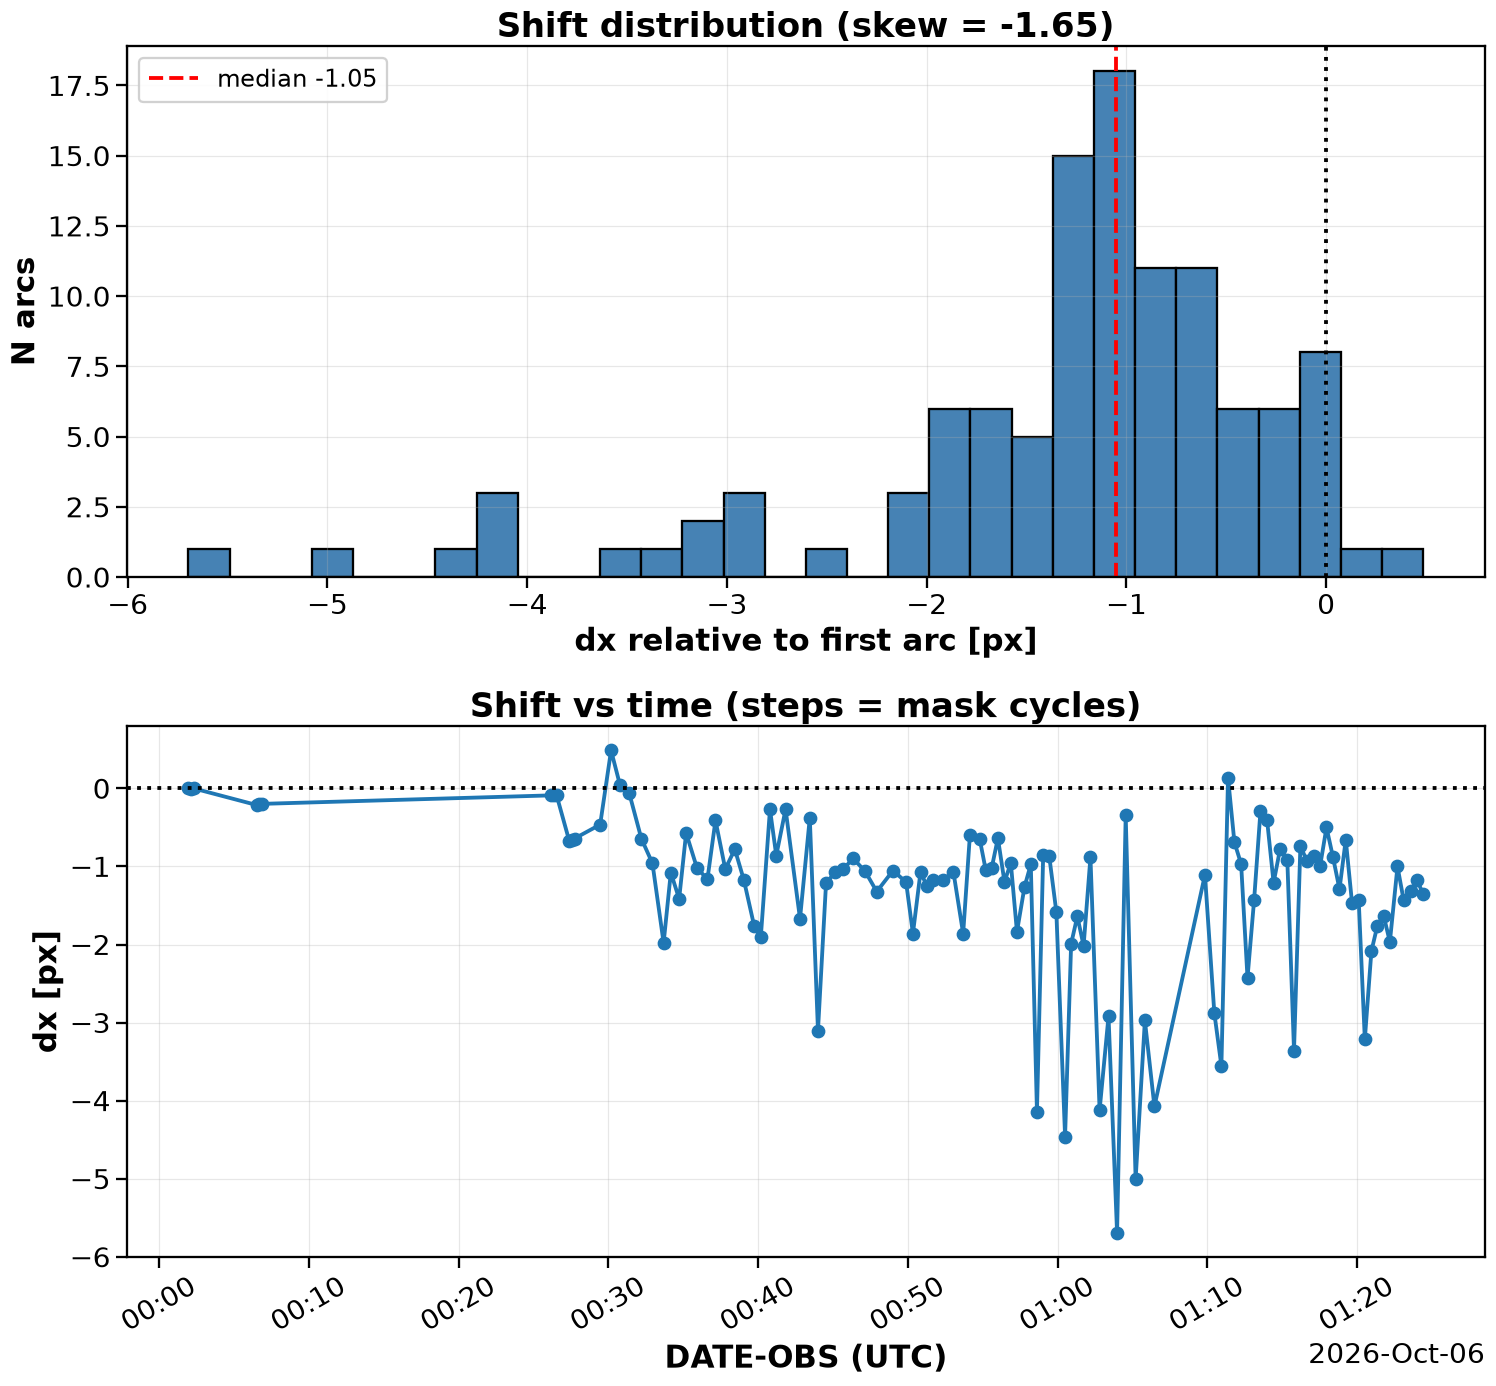

In [7]:
# Arcs that don't look like the reference (peak correlation << 0.9) give meaningless shifts:
# e.g. 0047/0049/0051 show a bright continuum and no lines. Flag and drop them.
MIN_CORR = 0.5
bad = shifts[shifts.peak_corr < MIN_CORR]
print(f"Dropping {len(bad)} arcs with peak_corr < {MIN_CORR}: {[os.path.basename(f) for f in bad.file]}")
shifts_ok = shifts[shifts.peak_corr >= MIN_CORR]

dx = shifts_ok["dx"].values
s = skew(dx)
p = skewtest(dx).pvalue if len(dx) >= 8 else np.nan

print(f"N = {len(dx)}")
print(f"mean = {dx.mean():+.3f} px | median = {np.median(dx):+.3f} px | std = {dx.std(ddof=1):.3f} px")
print(f"range = [{dx.min():+.3f}, {dx.max():+.3f}] px")
print(f"skewness = {s:+.3f}  (skewtest p = {p:.3g})")
print(f"fraction dx>0: {(dx > 0).mean():.2f} | dx<0: {(dx < 0).mean():.2f}")
print(f"min peak correlation = {shifts_ok.peak_corr.min():.3f}  (low values -> unreliable shift)")

fig, ax = plt.subplots(2, 1, figsize=(14, 13))
ax[0].hist(dx, bins=30, color="steelblue", edgecolor="k")
ax[0].axvline(0, color="k", ls=":")
ax[0].axvline(np.median(dx), color="r", ls="--", label=f"median {np.median(dx):+.2f}")
ax[0].set(xlabel="dx relative to first arc [px]", ylabel="N arcs", title=f"Shift distribution (skew = {s:+.2f})")
ax[0].legend()

ax[1].plot(shifts_ok["date_obs"], dx, "o-", ms=8)
ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="DATE-OBS (UTC)", ylabel="dx [px]", title="Shift vs time (steps = mask cycles)")
ax[1].tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


## Random reference arc

The first arc was an arbitrary reference anyway. Here the reference is a **random** arc instead. The seed is fixed, so the choice is the same on every run; change `SEED` to try another one. The pick is restricted to arcs that passed the quality cut, so a bad frame can't become the reference. The reference itself is again left out of the results, because its autocorrelation always gives a shift of 0.

Skewness doesn't change when every value moves by the same amount. If the skew was real, it should therefore survive a change of reference: only the zero point should move.

Random reference: 0014_arc_testing.fits (2026-10-06 00:26:31.851000)
N = 111 | median = -0.974 px | std = 1.109 px
skewness = -1.650  (skewtest p = 2.2e-08)
fraction dx>0: 0.07 | dx<0: 0.93


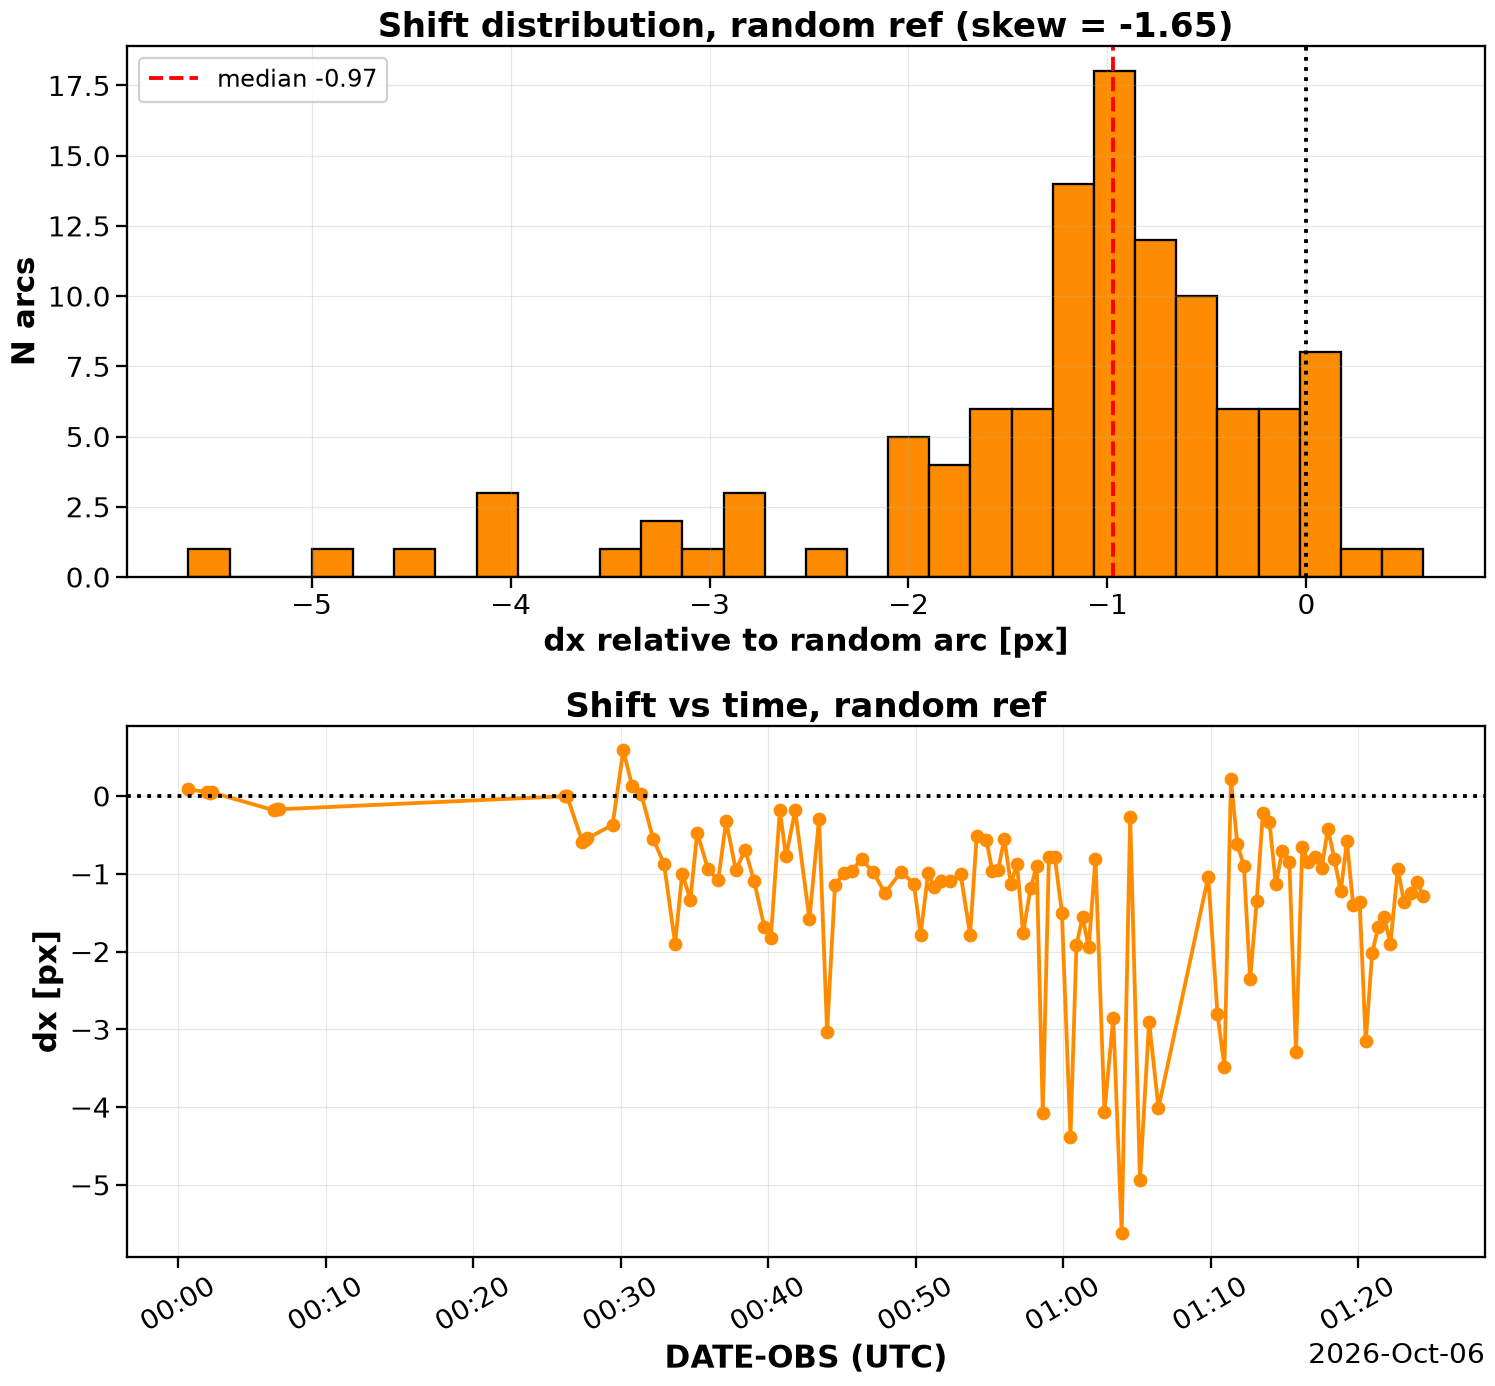

In [8]:
SEED = 42
rng = np.random.default_rng(SEED)

usable_arcs = [f for f in good_arcs if f not in set(bad.file)]
rand_ref_file = rng.choice(usable_arcs)
rand_ref = prepare_for_xcorr(spectra[rand_ref_file])

rows = []
for f in usable_arcs:
    if f == rand_ref_file:                   # skip autocorrelation with itself
        continue
    dx_f, peak = xcorr_shift(prepare_for_xcorr(spectra[f]), rand_ref)
    rows.append({"file": f, "dx": dx_f, "peak_corr": peak})

shifts_rand = pd.DataFrame(rows).merge(good[["file", "date_obs"]], on="file")
dxr = shifts_rand["dx"].values

print(f"Random reference: {os.path.basename(rand_ref_file)} "
      f"({good.loc[good.file == rand_ref_file, 'date_obs'].iloc[0]})")
print(f"N = {len(dxr)} | median = {np.median(dxr):+.3f} px | std = {dxr.std(ddof=1):.3f} px")
print(f"skewness = {skew(dxr):+.3f}  (skewtest p = {skewtest(dxr).pvalue:.3g})")
print(f"fraction dx>0: {(dxr > 0).mean():.2f} | dx<0: {(dxr < 0).mean():.2f}")

fig, ax = plt.subplots(2, 1, figsize=(14, 13))
ax[0].hist(dxr, bins=30, color="darkorange", edgecolor="k")
ax[0].axvline(0, color="k", ls=":")
ax[0].axvline(np.median(dxr), color="r", ls="--", label=f"median {np.median(dxr):+.2f}")
ax[0].set(xlabel="dx relative to random arc [px]", ylabel="N arcs",
          title=f"Shift distribution, random ref (skew = {skew(dxr):+.2f})")
ax[0].legend()
ax[1].plot(shifts_rand["date_obs"], dxr, "o-", ms=8, color="darkorange")
ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="DATE-OBS (UTC)", ylabel="dx [px]", title="Shift vs time, random ref")
ax[1].tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


## Does the shift depend on position along the spectrum?

If the **slit mask** moves, every line on the detector moves by the same number of pixels. A grating-angle or camera change would instead stretch or tilt the wavelength solution, so the shift would vary across the detector.

The test: split the dispersion axis into `N_SEG` segments and cross-correlate each segment against the same segment of the random reference.
- If the per-segment shifts agree for each arc, the shift is a constant offset (mask movement).
- If they differ systematically, for example a growing left-to-right gradient, something else is also changing.

`max_lag` is kept at 50 px, well below the segment width, so a segment can't lock onto the wrong line.

Median peak correlation per segment:
seg0_0-507_corr        0.951
seg1_507-1015_corr     0.989
seg2_1015-1522_corr    0.993
seg3_1522-2030_corr    0.993

Segment shift minus full-spectrum shift [px]:
      seg0_0-507  seg1_507-1015  seg2_1015-1522  seg3_1522-2030
mean       0.758         -0.055          -0.011           0.010
50%        0.279         -0.012           0.003           0.002
std        1.107          0.168           0.058           0.031
min       -0.627         -0.733          -0.263          -0.016
max        4.143          0.014           0.028           0.141

Segments used for gradient fit: ['seg1_507-1015', 'seg2_1015-1522', 'seg3_1522-2030']

Slope across detector: median +0.012 px/1000px, std 0.196
Correlation between full shift and slope: r = +0.26  (~0 -> pure offset; strong -> shift changes with position)


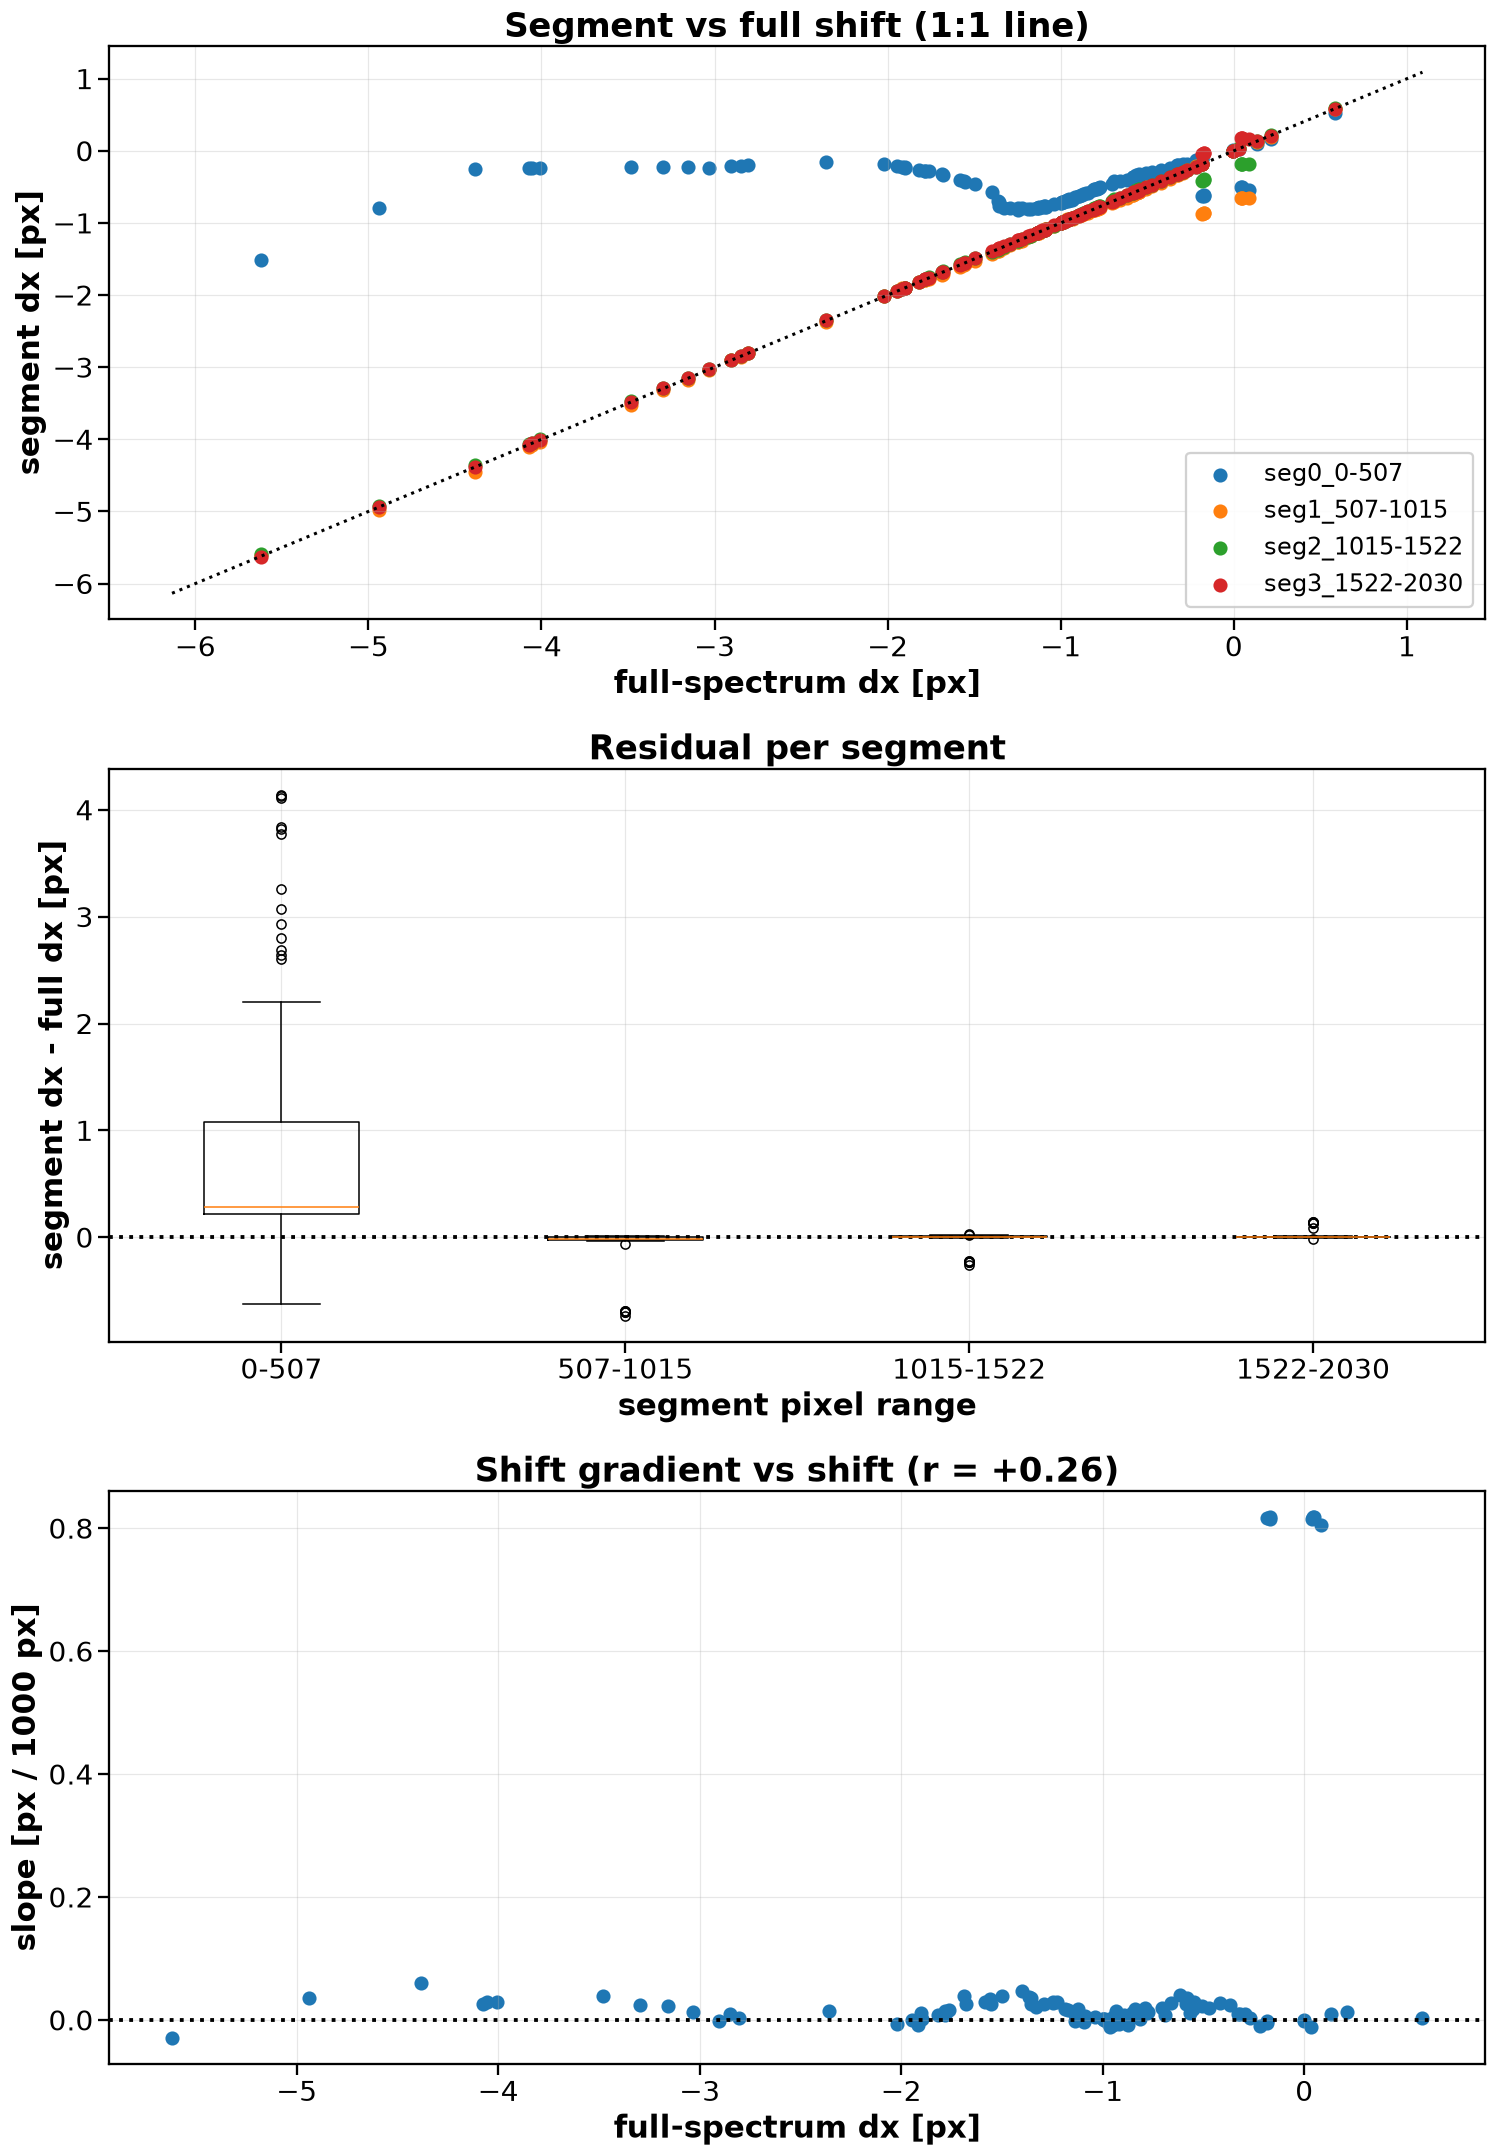

In [9]:
N_SEG = 4
n_pix = len(rand_ref)
edges = np.linspace(0, n_pix, N_SEG + 1).astype(int)
seg_names = [f"seg{i}_{edges[i]}-{edges[i+1]}" for i in range(N_SEG)]

def zscore(x):
    return (x - x.mean()) / x.std()

seg_rows = []
for f in shifts_rand["file"]:
    spec = prepare_for_xcorr(spectra[f])
    row = {"file": f}
    for name, a, b in zip(seg_names, edges[:-1], edges[1:]):
        row[name], row[name + "_corr"] = xcorr_shift(zscore(spec[a:b]), zscore(rand_ref[a:b]))
    seg_rows.append(row)

seg = shifts_rand[["file", "date_obs", "dx"]].merge(pd.DataFrame(seg_rows), on="file")

# segments are z-scored separately so peak_corr is comparable (~1 = identical line pattern);
# segments with few/weak lines give noisy shifts
print("Median peak correlation per segment:")
print(seg[[n + "_corr" for n in seg_names]].median().round(3).to_string())

# differences between each segment and the full-spectrum shift
diff = seg[seg_names].sub(seg["dx"], axis=0)
print("\nSegment shift minus full-spectrum shift [px]:")
print(diff.describe().loc[["mean", "50%", "std", "min", "max"]].round(3).to_string())

# Segments with too few lines are unreliable. Seg0 (blue end) has a single line plus a bright
# line clipped at the segment edge; the clipped edge doesn't move, so it drags the shift to ~0.
# Its median correlation looks fine (most arcs barely shift) but it collapses to ~0.4 for the
# large-shift arcs, so judge each segment on its worst arcs (10th percentile of peak_corr).
MIN_SEG_CORR = 0.9
good_segs = [n for n in seg_names if seg[n + "_corr"].quantile(0.1) >= MIN_SEG_CORR]
print(f"\nSegments used for gradient fit: {good_segs}")

# gradient: slope of shift vs segment centre, per arc
centres = 0.5 * (edges[:-1] + edges[1:])
good_centres = centres[[seg_names.index(n) for n in good_segs]]
seg["slope_px_per_1000px"] = [np.polyfit(good_centres, r, 1)[0] * 1000 for r in seg[good_segs].values]
r_slope = np.corrcoef(seg["dx"], seg["slope_px_per_1000px"])[0, 1]
print(f"\nSlope across detector: median {seg.slope_px_per_1000px.median():+.3f} px/1000px, "
      f"std {seg.slope_px_per_1000px.std():.3f}")
print(f"Correlation between full shift and slope: r = {r_slope:+.2f}  "
      "(~0 -> pure offset; strong -> shift changes with position)")

fig, ax = plt.subplots(3, 1, figsize=(14, 20))
for name in seg_names:
    ax[0].scatter(seg["dx"], seg[name], s=60, label=name)
lim = [seg[seg_names + ["dx"]].min().min() - 0.5, seg[seg_names + ["dx"]].max().max() + 0.5]
ax[0].plot(lim, lim, "k:", lw=2)
ax[0].set(xlabel="full-spectrum dx [px]", ylabel="segment dx [px]", title="Segment vs full shift (1:1 line)")
ax[0].legend()

ax[1].boxplot([diff[n] for n in seg_names])
ax[1].set_xticks(range(1, N_SEG + 1), [n.split("_")[1] for n in seg_names])
ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="segment pixel range", ylabel="segment dx - full dx [px]", title="Residual per segment")

ax[2].scatter(seg["dx"], seg["slope_px_per_1000px"], s=60)
ax[2].axhline(0, color="k", ls=":")
ax[2].set(xlabel="full-spectrum dx [px]", ylabel="slope [px / 1000 px]", title=f"Shift gradient vs shift (r = {r_slope:+.2f})")
plt.tight_layout()
plt.show()


## Redo without the problem arcs

Two groups of arcs are set aside **for now**. They aren't deleted; edit `EXCLUDE` to bring them back.
- **0047, 0049, 0051:** a bright continuum and no usable lines (peak correlation about 0.05).
- **0001–0007:** the first arcs of the night (00:00–00:07 UT). They show a stretch across the detector of about 0.8 px per 1000 px, which points to a grating or camera change rather than mask movement, so a single shift doesn't describe them.

Everything below reuses the functions defined above (`prepare_for_xcorr`, `xcorr_shift`, `zscore`). The random reference is re-drawn from the clean set with the same seed.

In [10]:
EXCLUDE = {"0047", "0049", "0051",            # no lines / continuum only
           "0001", "0002", "0003", "0004", "0005", "0006", "0007"}  # stretched (non-mask change)

clean_arcs = [f for f in good_arcs if os.path.basename(f)[:4] not in EXCLUDE]
print(f"{len(clean_arcs)} clean arcs ({len(good_arcs) - len(clean_arcs)} excluded)")

rng = np.random.default_rng(SEED)
ref_clean_file = rng.choice(clean_arcs)
ref_clean = prepare_for_xcorr(spectra[ref_clean_file])
print(f"Random reference: {os.path.basename(ref_clean_file)} "
      f"({good.loc[good.file == ref_clean_file, 'date_obs'].iloc[0]})")

rows = []
for f in clean_arcs:
    if f == ref_clean_file:                  # skip autocorrelation with itself
        continue
    spec = prepare_for_xcorr(spectra[f])
    row = {"file": f}
    row["dx"], row["peak_corr"] = xcorr_shift(spec, ref_clean)
    for name, a, b in zip(seg_names, edges[:-1], edges[1:]):
        row[name], row[name + "_corr"] = xcorr_shift(zscore(spec[a:b]), zscore(ref_clean[a:b]))
    rows.append(row)

clean = pd.DataFrame(rows).merge(good[["file", "date_obs"]], on="file").sort_values("date_obs")
print(f"min full-spectrum peak correlation: {clean.peak_corr.min():.3f}")


105 clean arcs (10 excluded)
Random reference: 0021_arc_testing.fits (2026-10-06 00:31:22.498000)


min full-spectrum peak correlation: 0.966


### Shift distribution and skew (clean set)

N = 104
mean = -1.335 px | median = -1.026 px | std = 1.101 px
range = [-5.655, +0.548] px
skewness = -1.673  (skewtest p = 3.93e-08)
fraction dx>0: 0.03 | dx<0: 0.97
robust sigma (MAD) = 0.606 px | arcs beyond 3 sigma: 12 (12 on the negative side)


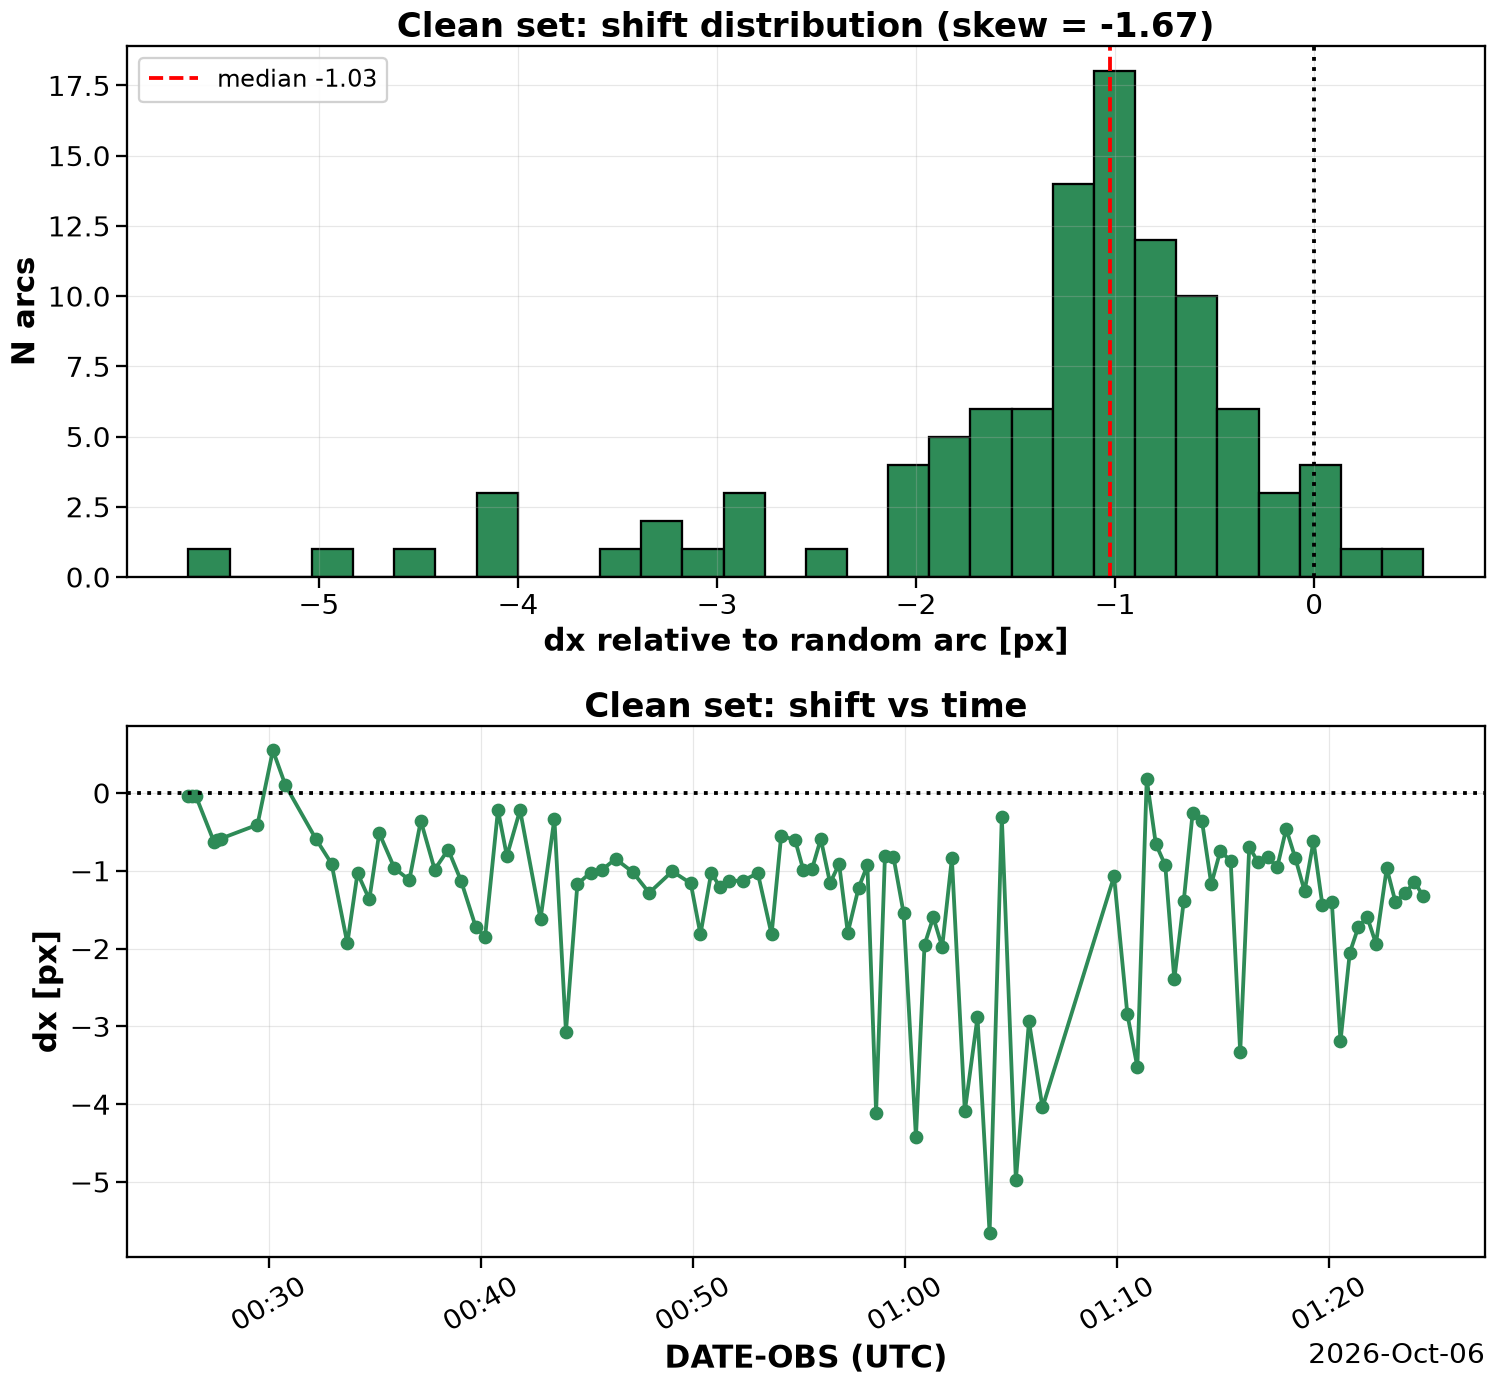

In [11]:
dxc = clean["dx"].values
print(f"N = {len(dxc)}")
print(f"mean = {dxc.mean():+.3f} px | median = {np.median(dxc):+.3f} px | std = {dxc.std(ddof=1):.3f} px")
print(f"range = [{dxc.min():+.3f}, {dxc.max():+.3f}] px")
print(f"skewness = {skew(dxc):+.3f}  (skewtest p = {skewtest(dxc).pvalue:.3g})")
print(f"fraction dx>0: {(dxc > 0).mean():.2f} | dx<0: {(dxc < 0).mean():.2f}")

# robust spread: core of the distribution vs the tail
mad = 1.4826 * np.median(np.abs(dxc - np.median(dxc)))
tail = np.abs(dxc - np.median(dxc)) > 3 * mad
print(f"robust sigma (MAD) = {mad:.3f} px | arcs beyond 3 sigma: {tail.sum()} "
      f"({(dxc[tail] < np.median(dxc)).sum()} on the negative side)")

fig, ax = plt.subplots(2, 1, figsize=(14, 13))
ax[0].hist(dxc, bins=30, color="seagreen", edgecolor="k")
ax[0].axvline(0, color="k", ls=":")
ax[0].axvline(np.median(dxc), color="r", ls="--", label=f"median {np.median(dxc):+.2f}")
ax[0].set(xlabel="dx relative to random arc [px]", ylabel="N arcs",
          title=f"Clean set: shift distribution (skew = {skew(dxc):+.2f})")
ax[0].legend()
ax[1].plot(clean["date_obs"], dxc, "o-", ms=8, color="seagreen")
ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="DATE-OBS (UTC)", ylabel="dx [px]", title="Clean set: shift vs time")
ax[1].tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


### Shift at different positions (clean set)

The same test as before. Segment 0 is still judged on its worst-arc correlation; if it fails the cut, it is left out of the gradient fit.

10th-percentile peak correlation per segment:
seg0_0-507_corr        0.490
seg1_507-1015_corr     0.969
seg2_1015-1522_corr    0.979
seg3_1522-2030_corr    0.975
Segments used for gradient fit: ['seg1_507-1015', 'seg2_1015-1522', 'seg3_1522-2030']

Segment shift minus full-spectrum shift [px]:
      seg0_0-507  seg1_507-1015  seg2_1015-1522  seg3_1522-2030
mean       0.854         -0.023           0.000           0.006
50%        0.281         -0.022          -0.001           0.006
std        1.109          0.016           0.006           0.004
min       -0.078         -0.085          -0.009          -0.012
max        4.200          0.004           0.024           0.016

Slope across detector: median +0.026 px/1000px, std 0.018, max |slope| 0.088
Correlation between full shift and slope: r = -0.16


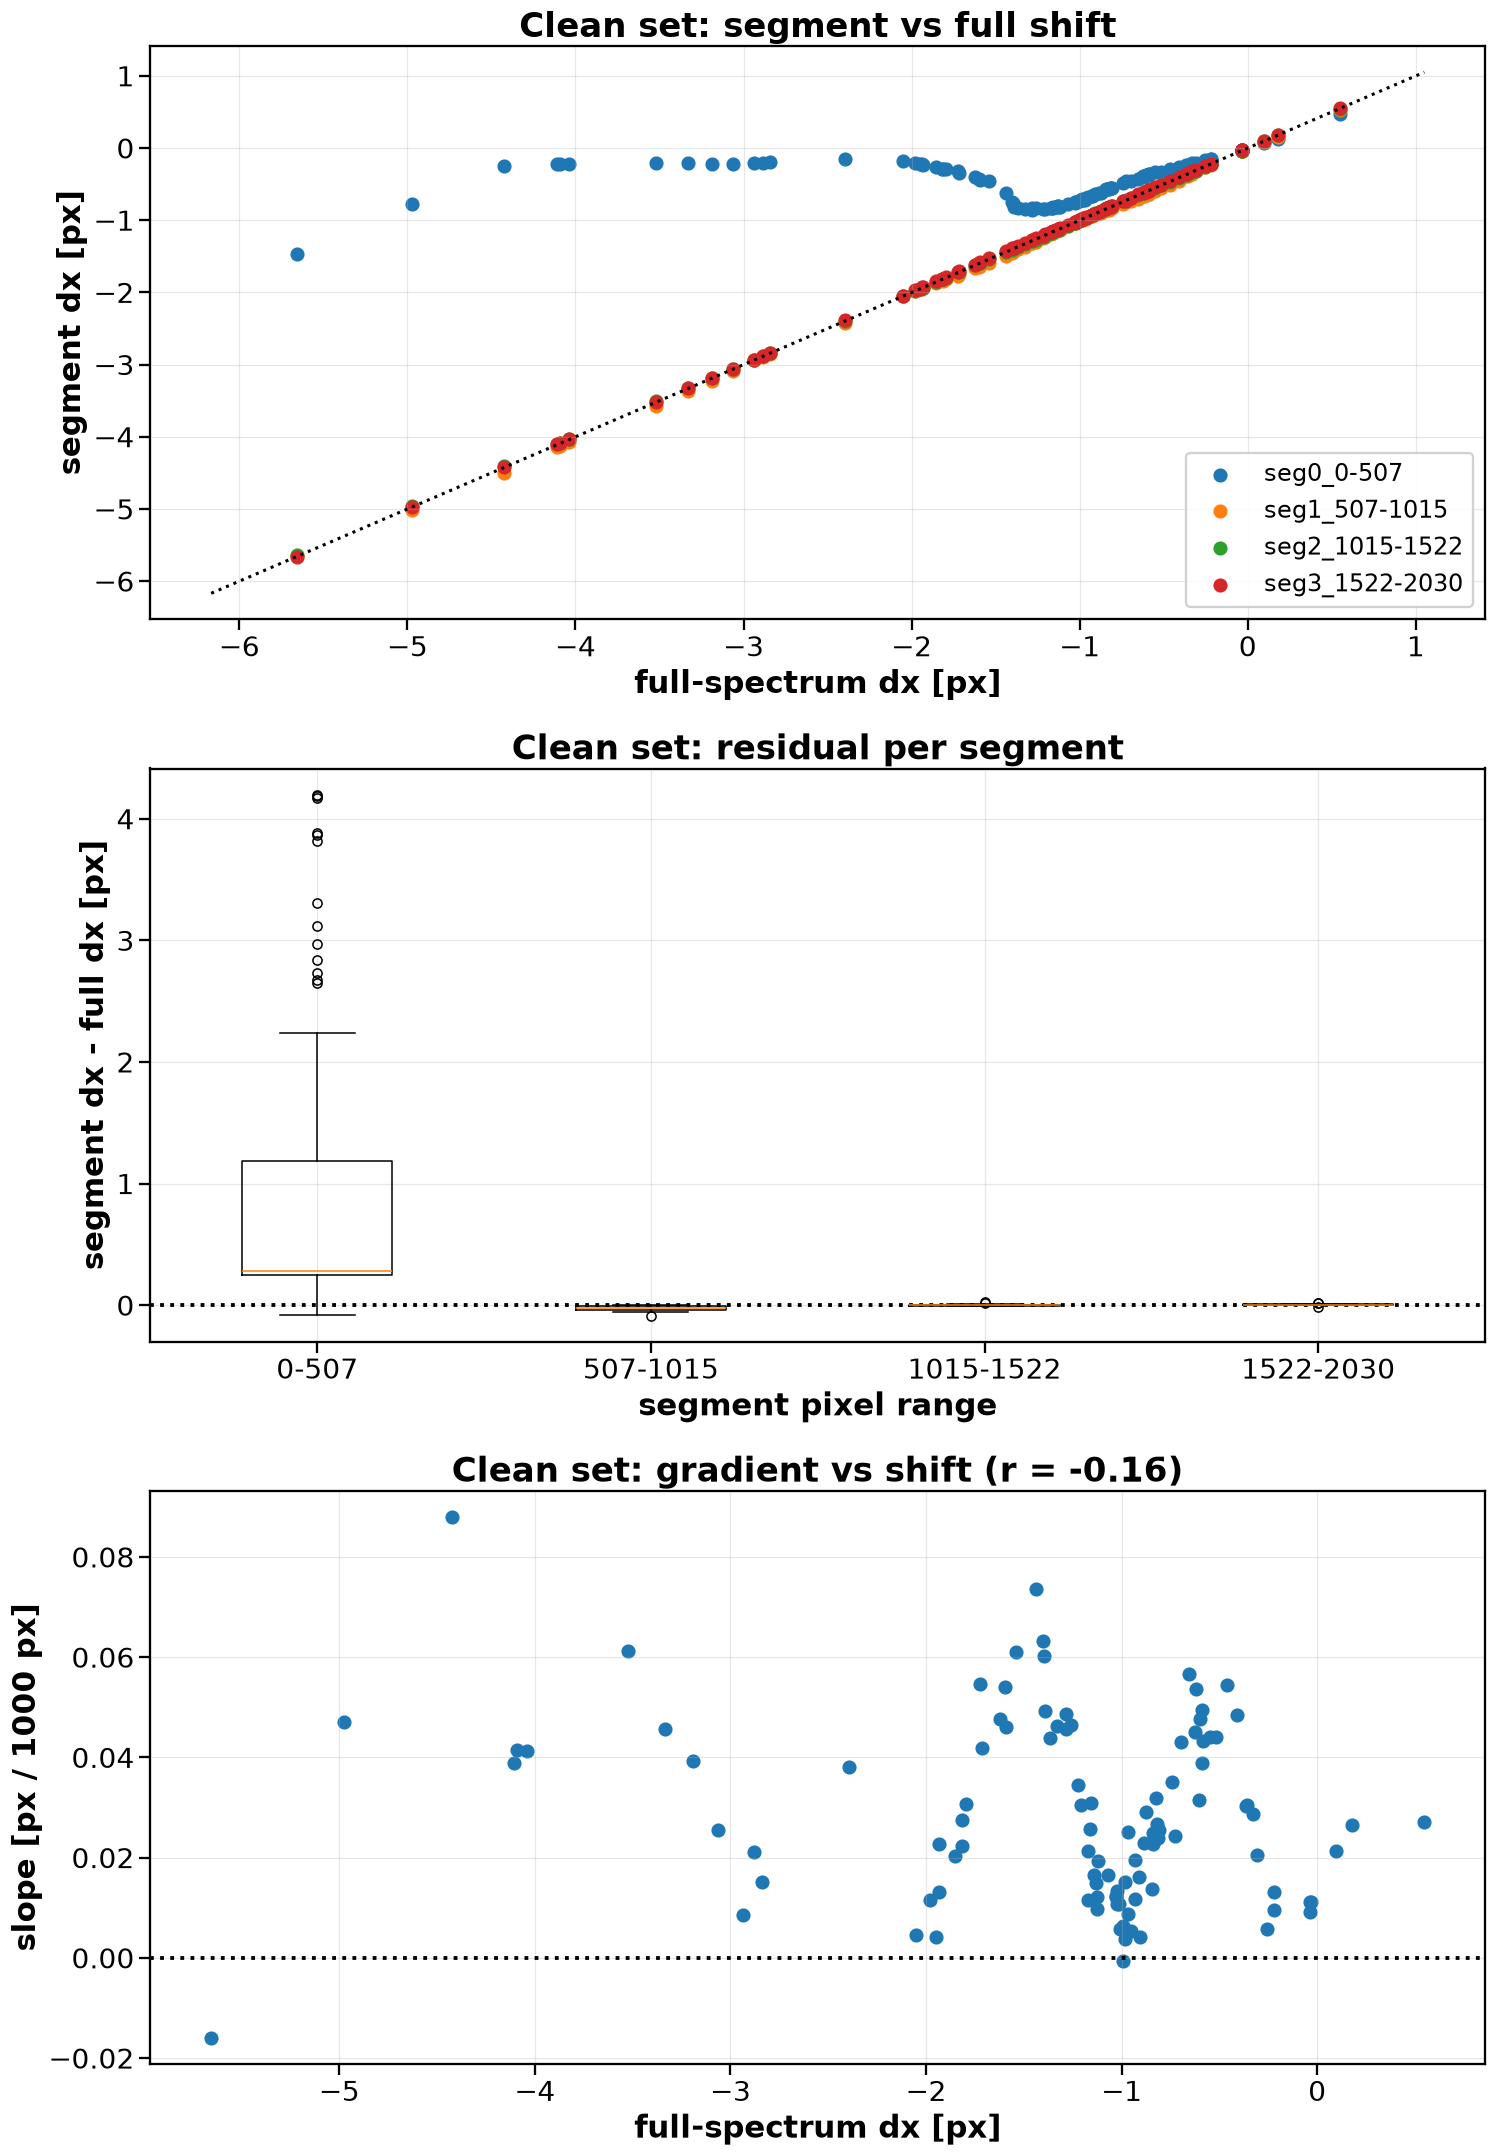

In [12]:
good_segs_c = [n for n in seg_names if clean[n + "_corr"].quantile(0.1) >= MIN_SEG_CORR]
print("10th-percentile peak correlation per segment:")
print(clean[[n + "_corr" for n in seg_names]].quantile(0.1).round(3).to_string())
print(f"Segments used for gradient fit: {good_segs_c}")

diff_c = clean[seg_names].sub(clean["dx"], axis=0)
print("\nSegment shift minus full-spectrum shift [px]:")
print(diff_c.describe().loc[["mean", "50%", "std", "min", "max"]].round(3).to_string())

gc = centres[[seg_names.index(n) for n in good_segs_c]]
clean["slope_px_per_1000px"] = [np.polyfit(gc, r, 1)[0] * 1000 for r in clean[good_segs_c].values]
r_c = np.corrcoef(clean["dx"], clean["slope_px_per_1000px"])[0, 1]
print(f"\nSlope across detector: median {clean.slope_px_per_1000px.median():+.3f} px/1000px, "
      f"std {clean.slope_px_per_1000px.std():.3f}, max |slope| {clean.slope_px_per_1000px.abs().max():.3f}")
print(f"Correlation between full shift and slope: r = {r_c:+.2f}")

fig, ax = plt.subplots(3, 1, figsize=(14, 20))
for name in seg_names:
    ax[0].scatter(clean["dx"], clean[name], s=60, label=name)
lim = [clean[seg_names + ["dx"]].min().min() - 0.5, clean[seg_names + ["dx"]].max().max() + 0.5]
ax[0].plot(lim, lim, "k:", lw=2)
ax[0].set(xlabel="full-spectrum dx [px]", ylabel="segment dx [px]", title="Clean set: segment vs full shift")
ax[0].legend()

ax[1].boxplot([diff_c[n] for n in seg_names])
ax[1].set_xticks(range(1, N_SEG + 1), [n.split("_")[1] for n in seg_names])
ax[1].axhline(0, color="k", ls=":")
ax[1].set(xlabel="segment pixel range", ylabel="segment dx - full dx [px]", title="Clean set: residual per segment")

ax[2].scatter(clean["dx"], clean["slope_px_per_1000px"], s=60)
ax[2].axhline(0, color="k", ls=":")
ax[2].set(xlabel="full-spectrum dx [px]", ylabel="slope [px / 1000 px]", title=f"Clean set: gradient vs shift (r = {r_c:+.2f})")
plt.tight_layout()
plt.show()


## Consecutive-pair shifts (clean set)

Instead of comparing every arc with one fixed reference, each clean arc is correlated with the **previous** clean arc in time (1→2, 2→3, …). The step is defined as `step_i = shift(arc_i relative to arc_{i-1})`.

Why this helps:
- It shows how far the mask moves **in a single cycle**, with no arbitrary reference involved.
- Arcs between which the mask was *not* cycled should give steps of about 0. The noise in those steps is the measurement floor.
- The steps should add up: their running total should reproduce the reference-based shifts from above, up to a constant. If it doesn't, the shift measurement itself has an error.
- The direction of the steps answers whether the mask drifts one way (steps mostly of one sign) or jumps around a home position (big steps followed by equal steps back).

Pairs separated by an excluded arc are still compared, since they are consecutive in the clean set. The time gap `dt` is kept so long gaps can be spotted.

In [13]:
clean_sorted = good[good.file.isin(clean_arcs)].sort_values("date_obs").reset_index(drop=True)

pair_rows = []
for prev, cur in zip(clean_sorted.itertuples(), clean_sorted.iloc[1:].itertuples()):
    step, peak = xcorr_shift(prepare_for_xcorr(spectra[cur.file]), prepare_for_xcorr(spectra[prev.file]))
    pair_rows.append({
        "pair": f"{os.path.basename(prev.file)[:4]}->{os.path.basename(cur.file)[:4]}",
        "file": cur.file,
        "date_obs": cur.date_obs,
        "dt_s": (cur.date_obs - prev.date_obs).total_seconds(),
        "step": step,
        "peak_corr": peak,
    })
pairs = pd.DataFrame(pair_rows)

# Closure check: cumulative steps vs shifts measured against the random reference (clean set).
# Both are relative positions, so compare after removing their medians.
pairs["cum"] = pairs["step"].cumsum()
chk = pairs.merge(clean[["file", "dx"]], on="file")
resid = (chk["cum"] - chk["cum"].median()) - (chk["dx"] - chk["dx"].median())
print(f"{len(pairs)} consecutive pairs | min peak correlation {pairs.peak_corr.min():.3f}")
print(f"Closure check (cumulative steps vs reference shifts): "
      f"median |resid| = {resid.abs().median():.3f} px, max = {resid.abs().max():.3f} px")


104 consecutive pairs | min peak correlation 0.970
Closure check (cumulative steps vs reference shifts): median |resid| = 0.045 px, max = 0.117 px


back-to-back pairs (dt < 15s): 4 | their |step| max = 0.020 px -> noise floor ~ 0.009 px, 'moved' threshold = 0.050 px
cycled pairs (dt >= 15s): 100 | median -0.099 px | median |step| 0.572 px | std 1.407 px
pairs that moved: 94 of 104 (43 positive, 51 negative)
skewness of cycled steps = +0.245  (skewtest p = 0.293)
lag-1 autocorrelation of steps = -0.61  (-0.5: returns to a home position, 0: random walk)

Largest steps:
      pair                date_obs  dt_s   step  peak_corr
0081->0082 2026-10-06 01:04:32.806  34.6  5.317      0.976
0082->0083 2026-10-06 01:05:12.591  39.8 -4.666      0.984
0088->0089 2026-10-06 01:11:22.921  26.5  3.725      0.989
0070->0071 2026-10-06 00:59:02.100  25.0  3.300      0.987
0078->0079 2026-10-06 01:02:48.227  36.7 -3.253      0.990
0069->0070 2026-10-06 00:58:37.139  24.6 -3.179      0.995
0085->0086 2026-10-06 01:09:50.437 202.5  2.970      0.999
0073->0074 2026-10-06 01:00:29.874  35.1 -2.904      0.998
0080->0081 2026-10-06 01:03:58.253  34.3 -2

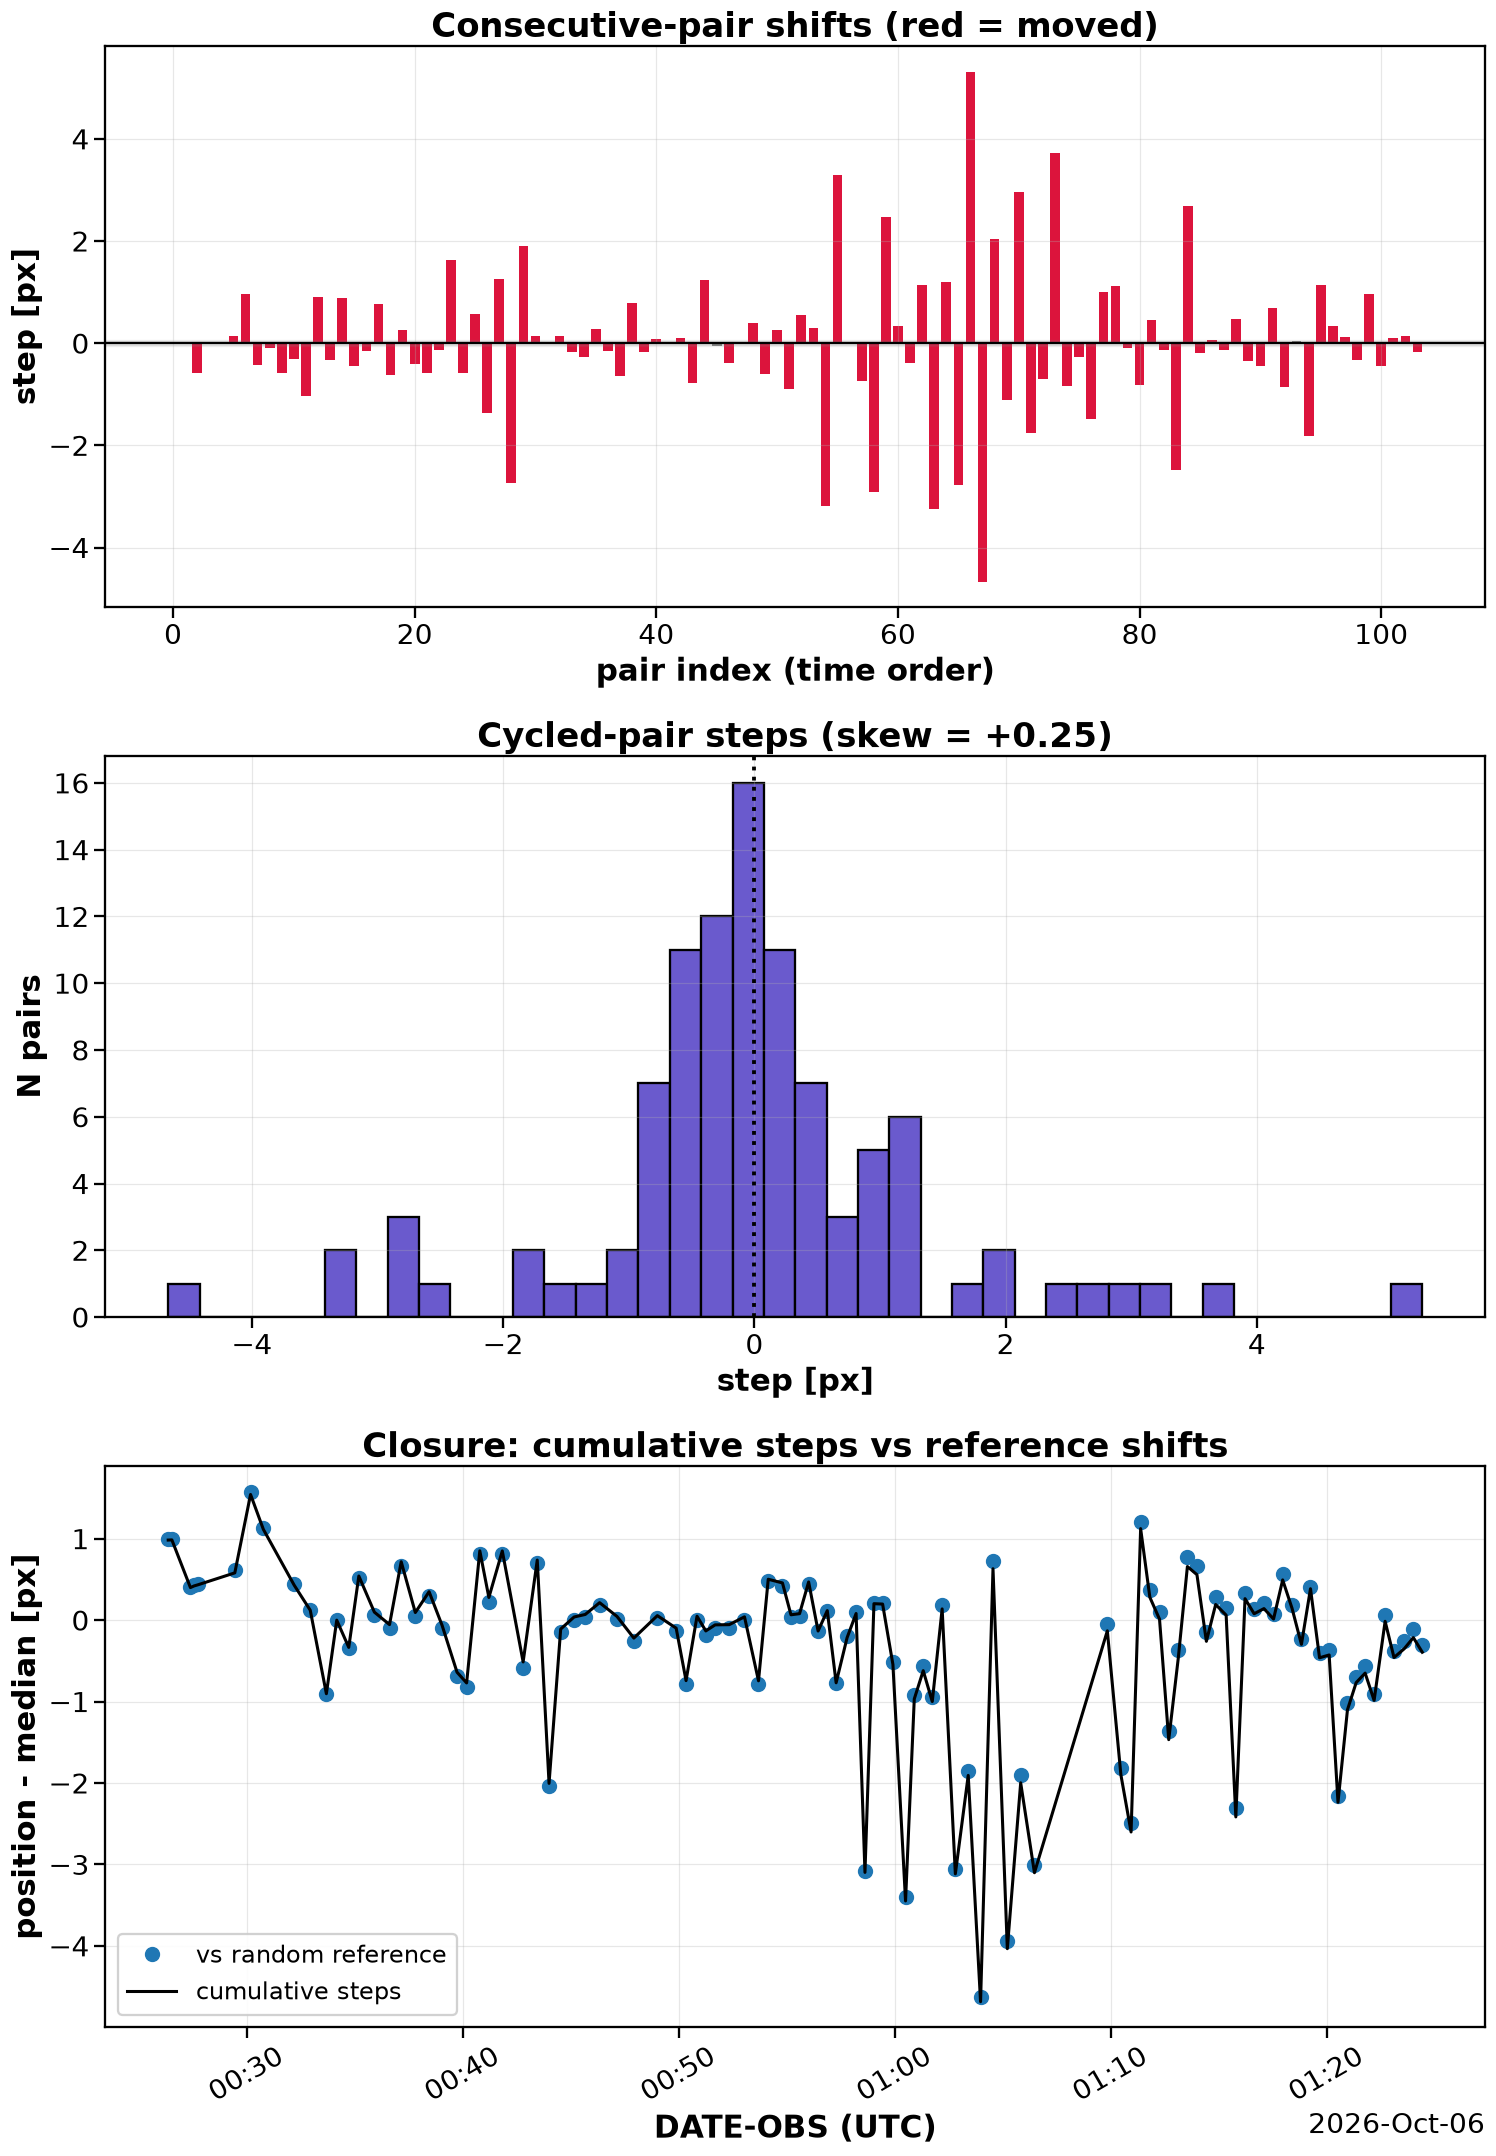

In [14]:
st = pairs["step"].values
# Pairs taken ~10 s apart are back-to-back repeats with no mask cycle in between: their step is the
# measurement noise floor. Pairs >~25 s apart had a cycle in between.
QUICK_DT = 15  # s
quick = pairs["dt_s"].values < QUICK_DT
noise = st[quick].std(ddof=1) if quick.sum() > 1 else np.nan
thresh = max(5 * noise, 0.05)
moved = np.abs(st) > thresh

print(f"back-to-back pairs (dt < {QUICK_DT}s): {quick.sum()} | their |step| max = {np.abs(st[quick]).max():.3f} px "
      f"-> noise floor ~ {noise:.3f} px, 'moved' threshold = {thresh:.3f} px")
cyc = st[~quick]
print(f"cycled pairs (dt >= {QUICK_DT}s): {len(cyc)} | median {np.median(cyc):+.3f} px | "
      f"median |step| {np.median(np.abs(cyc)):.3f} px | std {cyc.std(ddof=1):.3f} px")
print(f"pairs that moved: {moved.sum()} of {len(st)} "
      f"({(st[moved] > 0).sum()} positive, {(st[moved] < 0).sum()} negative)")
print(f"skewness of cycled steps = {skew(cyc):+.3f}  (skewtest p = {skewtest(cyc).pvalue:.3g})")

# Do big jumps come back? Correlation between consecutive steps:
# ~ -0.5 -> jump away then jump back (random positions around a home); ~0 -> independent steps (random walk)
lag1 = np.corrcoef(st[:-1], st[1:])[0, 1]
print(f"lag-1 autocorrelation of steps = {lag1:+.2f}  (-0.5: returns to a home position, 0: random walk)")

print("\nLargest steps:")
print(pairs.reindex(pairs.step.abs().sort_values(ascending=False).index)
      [["pair", "date_obs", "dt_s", "step", "peak_corr"]].head(12).round({"dt_s": 1, "step": 3, "peak_corr": 3})
      .to_string(index=False))

fig, ax = plt.subplots(3, 1, figsize=(14, 20))
ax[0].bar(range(len(st)), st, color=np.where(moved, "crimson", "grey"))
ax[0].axhspan(-thresh, thresh, color="grey", alpha=0.15)
ax[0].axhline(0, color="k", lw=1.5)
ax[0].set(xlabel="pair index (time order)", ylabel="step [px]", title="Consecutive-pair shifts (red = moved)")

ax[1].hist(cyc, bins=40, color="slateblue", edgecolor="k")
ax[1].axvline(0, color="k", ls=":")
ax[1].set(xlabel="step [px]", ylabel="N pairs", title=f"Cycled-pair steps (skew = {skew(cyc):+.2f})")

ax[2].plot(chk["date_obs"], chk["dx"] - chk["dx"].median(), "o", ms=9, label="vs random reference")
ax[2].plot(chk["date_obs"], chk["cum"] - chk["cum"].median(), "-", lw=2, color="k", label="cumulative steps")
ax[2].set(xlabel="DATE-OBS (UTC)", ylabel="position - median [px]", title="Closure: cumulative steps vs reference shifts")
ax[2].legend()
ax[2].tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


# Part 2: Classical vs AEON comparison

**Data**
- `classical_night_arcs/`: the 2026-10-05 test night analysed above. The pattern was arc → mask cycled → arc, with the **telescope parked** (elevation 88.5°, rotator fixed at 360°). It is a *control*: the only thing that changes between arcs is the mask cycle.
- `aeon_night_arcs/`: 381 arcs from 37 AEON nights (Dec 2025 – Jun 2026). Each science block takes about 3 arcs back-to-back, with the mask cycled for acquisition between blocks. The telescope points at different targets, so the **rotator angle, elevation, temperature, and camera angle all change**.

**Selection:** 400_M1, HgAr+Ne, `1.0_LONG_SLIT`. The few 1.5″ slit arcs are a different slit, so they would have a different position and are excluded. The **red and blue cameras** (`INSTRUME`) are different detectors, so they are always analysed separately. The classical night has only red-camera arcs.

**Approach**
1. Shifts are measured against a **template per camera**. For red, it is the median-stacked classical clean arcs, so 0 px means "where the classical night sat". For blue there are no classical arcs, so it is the median-stacked AEON blue arcs.
2. AEON shifts reach tens of pixels, so the correlation search window is widened to ±300 px. A per-segment consistency check (same idea as before) catches a correlation that locks onto the wrong line.
3. Consecutive arcs less than 20 s apart form a **block**: same target, no mask cycle in between. Spread within a block measures repeatability *without* cycling. Differences between blocks include a cycle.
4. The shifts are compared against header values: rotator, elevation, camera and grating angles, temperatures, exposure time, and date.

In [15]:
AEON_DIR = "/Users/ani/local/data/soar/slit_test/aeon_night_arcs"
CLAS_DIR = "/Users/ani/local/data/soar/slit_test/classical_night_arcs"

def header_row(f):
    """Header of the image HDU (HDU 1 for .fits.fz, HDU 0 for plain .fits)."""
    with fits.open(f) as hl:
        h = hl[1].header if len(hl) > 1 else hl[0].header
    return {
        "file": f, "bn": os.path.basename(f),
        "instr": str(h.get("INSTRUME", "")).strip().lower(),
        "obstype": str(h.get("OBSTYPE", "")).strip().upper(),
        "wavmode": str(h.get("WAVMODE", "")).strip().upper().replace("400M1", "400_M1"),
        "slit": h.get("SLIT"), "lamp": find_lamp_type(h),
        "date_obs": h.get("DATE-OBS"), "exptime": h.get("EXPTIME"),
        "rotator": h.get("ROTATOR"), "posangle": h.get("POSANGLE"),
        "mount_az": h.get("MOUNT_AZ"), "mount_el": h.get("MOUNT_EL"),
        "cam_ang": h.get("CAM_ANG"), "grt_ang": h.get("GRT_ANG"),
        "cam_foc": h.get("CAM_FOC"), "coll_foc": h.get("COLL_FOC"),
        "cam_temp": h.get("CAM_TEMP"), "col_temp": h.get("COL_TEMP"), "env_temp": h.get("ENVTEM"),
        "object": h.get("OBJECT"), "block_id": h.get("BLOCK_ID"),
    }

hdr = pd.DataFrame(
    [header_row(f) | {"set": "classical"} for f in sorted(glob.glob(os.path.join(CLAS_DIR, "*.fits")))] +
    [header_row(f) | {"set": "aeon"} for f in sorted(glob.glob(os.path.join(AEON_DIR, "*.fits.fz")))]
)
hdr["date_obs"] = pd.to_datetime(hdr["date_obs"])

sel = hdr[hdr.obstype.isin(["ARC", "COMP"]) & (hdr.wavmode == "400_M1") &
          (hdr.lamp == "HgAr+Ne") & (hdr.slit == "1.0_LONG_SLIT")].copy()

# reuse the clean-set exclusions from Part 1 for the classical night
sel = sel[~((sel.set == "classical") & sel.bn.str[:4].isin(EXCLUDE))]
sel = sel.sort_values("date_obs").reset_index(drop=True)
print(sel.groupby(["set", "instr"]).size().rename("n_arcs").to_string())

set        instr    
aeon       ghts_blue     63
           ghts_red     195
classical  ghts_red     105


In [16]:
# extract 1D spectra (same extraction as Part 1; works for .fits.fz too)
spec2 = {f: extract_1d_arc_spectrum(f) for f in sel.file}
prep2 = {f: prepare_for_xcorr(s) for f, s in spec2.items()}

# saturation check: AEON lines are often saturated (65535) which flattens peaks
sel["peak_adu"] = [spec2[f].max() for f in sel.file]
print(sel.groupby(["set", "instr"]).peak_adu.describe()[["min", "50%", "max"]].round(0).to_string())


                         min      50%      max
set       instr                               
aeon      ghts_blue  41205.0  65534.0  65534.0
          ghts_red   36856.0  55508.0  56464.0
classical ghts_red   33887.0  39233.0  40890.0


## Shifts against a per-camera template

`build_template` aligns arcs to a seed spectrum with sub-pixel interpolation, median-stacks them, and repeats a few times. Each arc's shift `dx` is then measured against the template.

`MAX_LAG = 300 px`, because AEON shifts go well beyond the ±50 px used in Part 1.

**Aliasing and stretch check:** the detector is split into 3 segments (pixels 507–2030; the blue end has too few lines). Each segment's shift is measured *near* the full-spectrum shift: the arc is first moved by `-dx`, then a ±10 px search is done. A wide search on a short segment can lock onto a neighbouring line.
- `alias_flag`: a segment needed more than 5 px of extra shift, so the full-spectrum match is suspect.
- `stretch`: the slope of segment shift against pixel, in px per 1000 px. It is ~0 for a pure translation (mask movement) and non-zero for a change in dispersion (camera/grating angle, temperature).

In [17]:
from scipy.ndimage import shift as subpix_shift

MAX_LAG = 300
SEG_EDGES = [(507, 1015), (1015, 1522), (1522, 2030)]
SEG_CENTRES = np.array([0.5 * (a + b) for a, b in SEG_EDGES])

def segment_shifts(s, T, dx_full, local_lag=10):
    """Per-segment shift, searched within +-local_lag px of the full-spectrum shift."""
    s_al = subpix_shift(s, -dx_full, order=3, mode="nearest")
    return [dx_full + xcorr_shift(zscore(s_al[a:b]), zscore(T[a:b]), local_lag)[0] for a, b in SEG_EDGES]

def build_template(files, seed, n_iter=3):
    ref = prep2[seed]
    for _ in range(n_iter):
        aligned = [subpix_shift(prep2[f], -xcorr_shift(prep2[f], ref, MAX_LAG)[0], order=3, mode="nearest")
                   for f in files]
        ref = zscore(np.median(aligned, axis=0))
    return ref

templates = {}
templates["ghts_red"] = build_template(list(sel[(sel.set == "classical")].file),
                                       seed=sel[sel.set == "classical"].file.iloc[0])
blue_files = list(sel[sel.instr == "ghts_blue"].file)
# seed the blue template with the blue arc that best matches the others (highest median correlation)
blue_seed = max(blue_files[::3], key=lambda s: np.median([xcorr_shift(prep2[f], prep2[s], MAX_LAG)[1] for f in blue_files]))
templates["ghts_blue"] = build_template(blue_files, seed=blue_seed)

rows = []
for r in sel.itertuples():
    T, s = templates[r.instr], prep2[r.file]
    dx_, pc_ = xcorr_shift(s, T, MAX_LAG)
    segs = segment_shifts(s, T, dx_)
    rows.append({"file": r.file, "dx": dx_, "peak_corr": pc_, "seg_dx": segs})
sh2 = sel.merge(pd.DataFrame(rows), on="file")
sh2["stretch"] = [np.polyfit(SEG_CENTRES, v, 1)[0] * 1000 for v in sh2.seg_dx]   # px per 1000 px
sh2["alias_flag"] = [np.max(np.abs(np.array(v) - d)) > 5.0 for v, d in zip(sh2.seg_dx, sh2.dx)]
sh2["low_corr"] = sh2.peak_corr < 0.5

print(sh2.groupby(["set", "instr"]).agg(n=("dx", "size"), alias=("alias_flag", "sum"),
                                        low_corr=("low_corr", "sum"),
                                        min_corr=("peak_corr", "min"),
                                        stretch_med=("stretch", "median"),
                                        stretch_min=("stretch", "min"),
                                        stretch_max=("stretch", "max")).round(3).to_string())
print("\nFlagged arcs:")
print(sh2[sh2.alias_flag | sh2.low_corr][["bn", "instr", "dx", "peak_corr", "seg_dx"]]
      .assign(seg_dx=lambda d: d.seg_dx.apply(lambda v: np.round(v, 1))).to_string(index=False))


                       n  alias  low_corr  min_corr  stretch_med  stretch_min  stretch_max
set       instr                                                                           
aeon      ghts_blue   63      1         2     0.082       -0.033       -0.834        7.735
          ghts_red   195      0         0     0.526        1.371        0.265        2.434
classical ghts_red   105      0         0     0.969       -0.004       -0.042        0.040

Flagged arcs:
                                           bn     instr          dx  peak_corr                   seg_dx
    0199_ZTF26aaffxis_17-02-2026_comp.fits.fz ghts_blue  -19.616420   0.458164    [-20.2, -19.7, -19.3]
0189_Calibration-Star_13-06-2026_comp.fits.fz ghts_blue -245.168259   0.082040 [-251.5, -244.2, -243.6]


In [18]:
# keep only trustworthy measurements
ok2 = sh2[~sh2.alias_flag & ~sh2.low_corr].copy()

# blocks: consecutive arcs (same camera) less than 20 s apart -> no mask cycle in between.
# Back-to-back repeats are ~10-11 s apart (classical and AEON); arcs with a cycle in between are >= ~25 s apart.
BLOCK_GAP = 20  # s
ok2 = ok2.sort_values(["instr", "date_obs"])
gap = ok2.groupby("instr").date_obs.diff().dt.total_seconds()
ok2["block"] = (gap.isna() | (gap > BLOCK_GAP)).cumsum()
# AEON night label (local night: shift UT by 12 h)
ok2["night"] = (ok2.date_obs - pd.Timedelta(hours=12)).dt.date

blk = ok2.groupby("block").agg(
    set=("set", "first"), instr=("instr", "first"), night=("night", "first"),
    t=("date_obs", "first"), n=("dx", "size"), dx=("dx", "median"),
    spread=("dx", lambda v: np.ptp(v)),
    rotator=("rotator", "median"), mount_el=("mount_el", "median"), mount_az=("mount_az", "median"),
    cam_ang=("cam_ang", "median"), grt_ang=("grt_ang", "median"),
    cam_temp=("cam_temp", "median"), col_temp=("col_temp", "median"), env_temp=("env_temp", "median"),
    exptime=("exptime", "median"), stretch=("stretch", "median"), cam_foc=("cam_foc", "median"), obj=("object", "first"),
).reset_index()

print(blk.groupby(["set", "instr"]).agg(n_blocks=("dx", "size"), arcs_per_block=("n", "median"),
                                        max_within_block_spread=("spread", "max"),
                                        median_within_block_spread=("spread", "median")).round(3).to_string())


                     n_blocks  arcs_per_block  max_within_block_spread  median_within_block_spread
set       instr                                                                                   
aeon      ghts_blue        24             3.0                    3.068                       0.023
          ghts_red         87             3.0                    6.605                       0.018
classical ghts_red        101             1.0                    0.040                       0.000


## Q1: Do classical and AEON show similar shifts?

The comparison is at two levels:
1. **No cycle:** repeat arcs taken back-to-back. These are the classical 10 s pairs and the arcs within one AEON block.
2. **Across cycles:** the overall shift distribution, and the change between consecutive blocks *within the same night*. Comparing within a night removes slow drifts and the era change (see Q4).

                                                         N  median    std  robust_sigma    min    max  skew
aeon      ghts_blue all positions (dx)                24.0   -1.16  19.67         21.77 -46.75  27.20 -0.32
                    step between blocks, same night   19.0    0.31   8.61          7.50 -11.98  27.23  1.45
          ghts_red  all positions (dx)                87.0   12.82  20.45         28.14 -52.18  34.85 -0.52
                    step between blocks, same night   55.0    0.58   7.05          8.04 -15.75  22.65  0.14
classical ghts_red  all positions (dx)               101.0   -1.00   1.11          0.60  -5.62   0.58 -1.65
                    step between blocks, same night  100.0   -0.10   1.41          0.73  -4.67   5.35  0.25


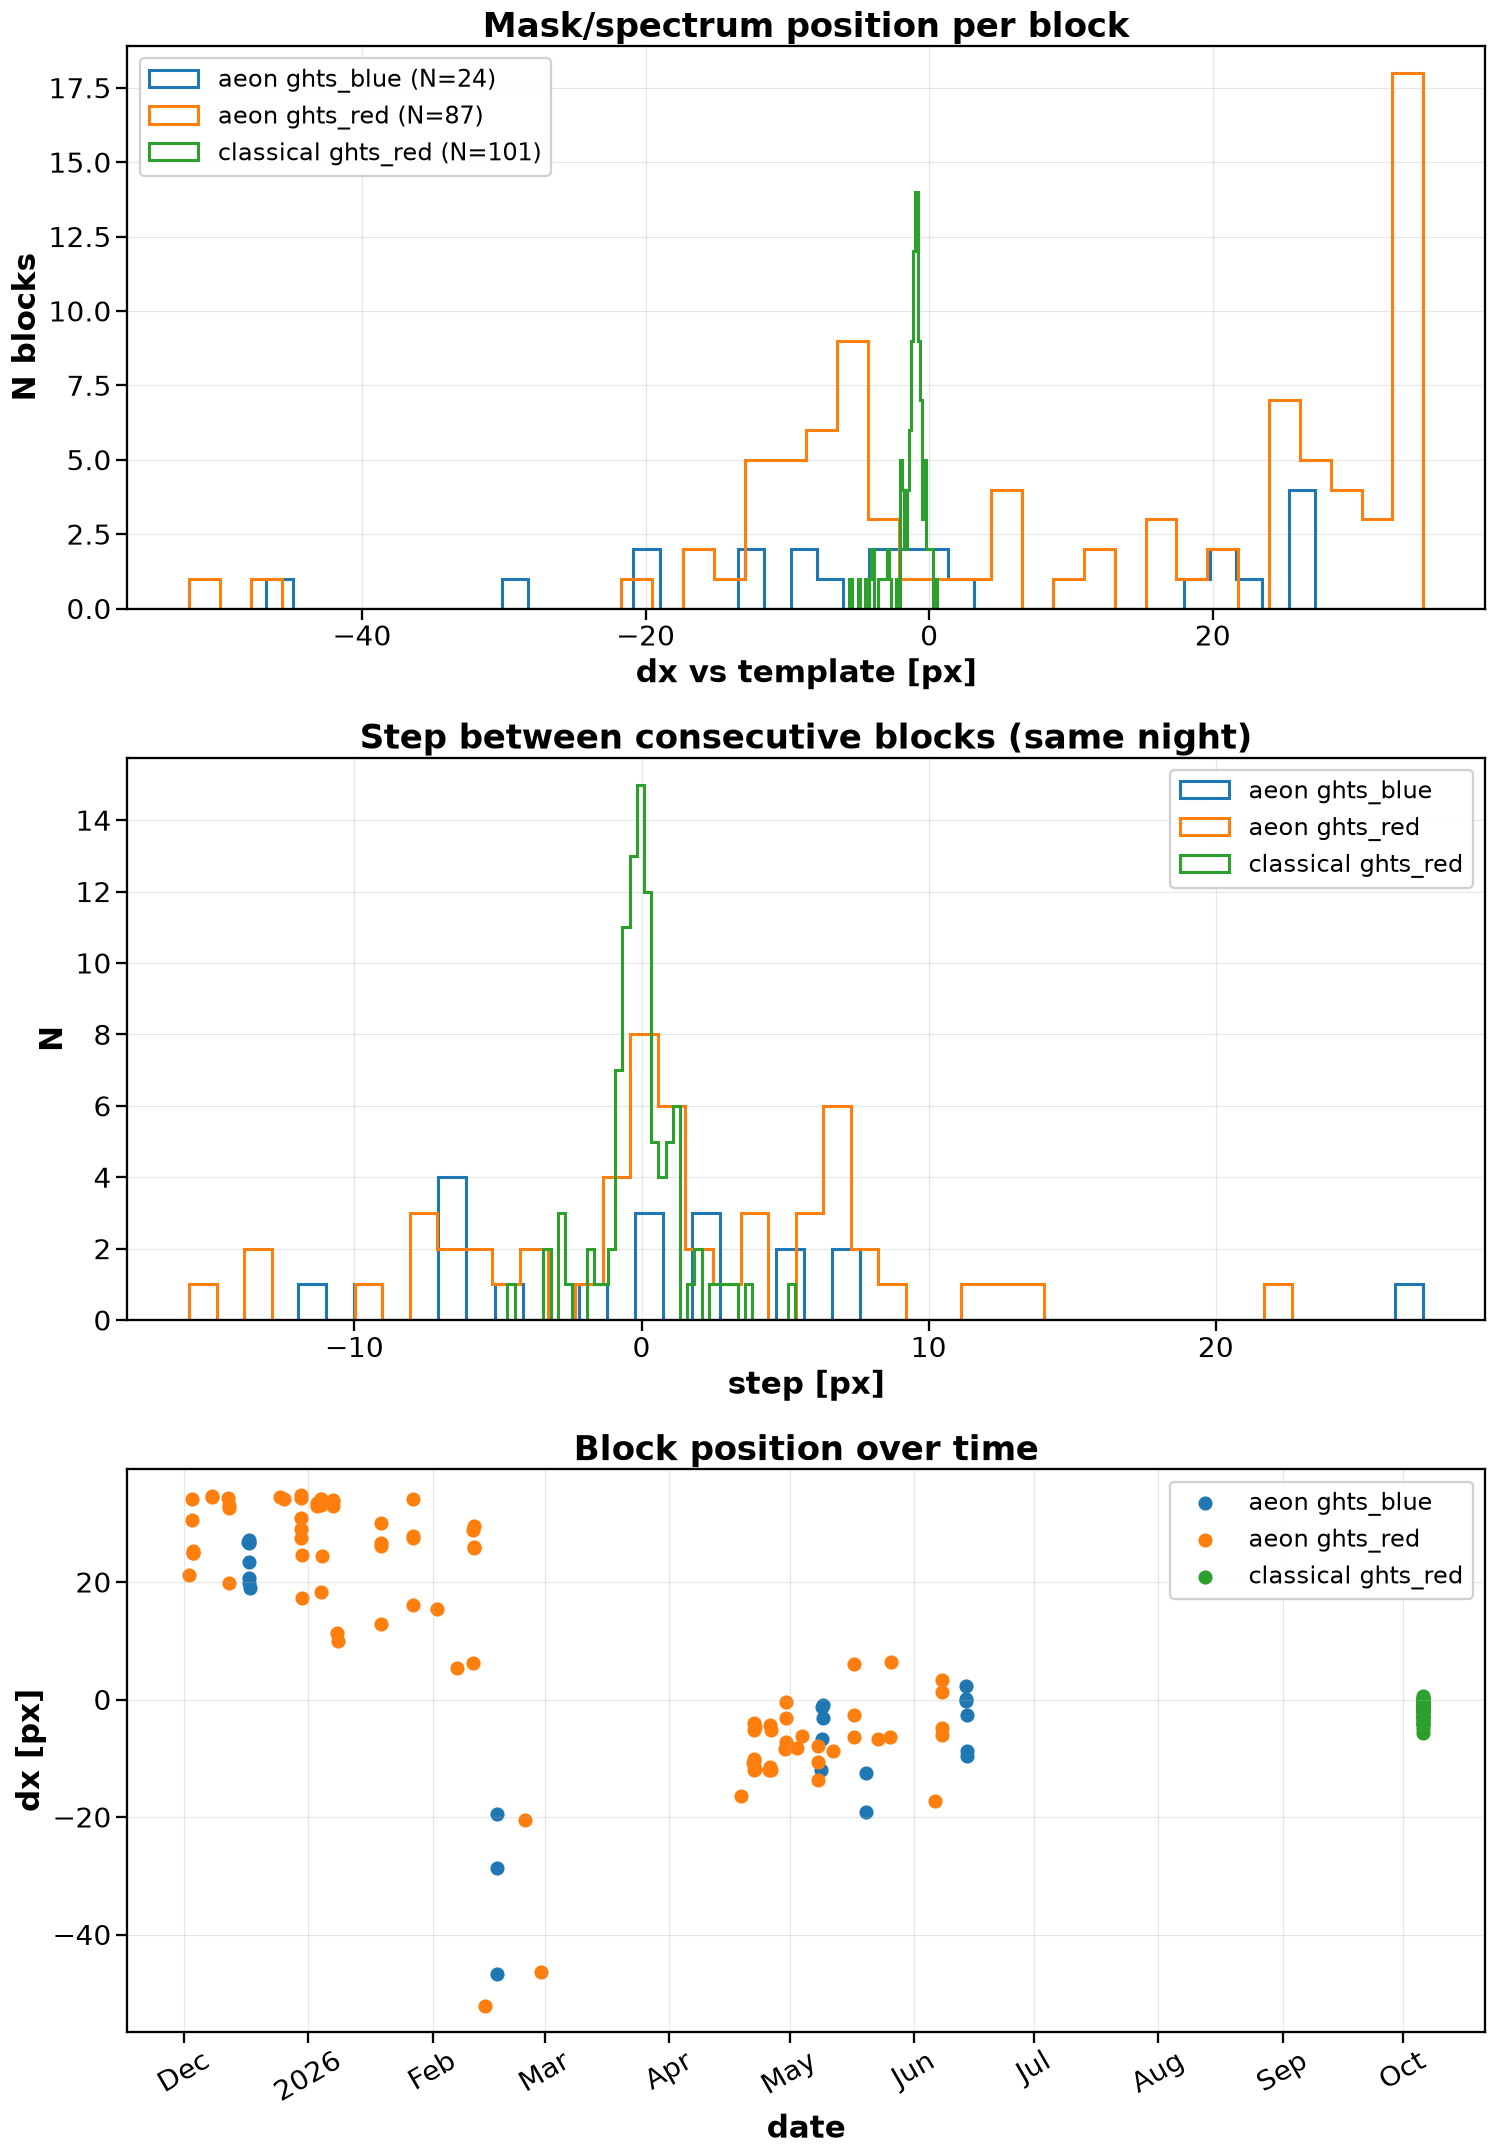

In [19]:
mad_ = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))

def summarize(v):
    v = np.asarray(v)
    return pd.Series({"N": len(v), "median": np.median(v), "std": v.std(ddof=1), "robust_sigma": mad_(v),
                      "min": v.min(), "max": v.max(), "skew": skew(v)})

# block-to-block steps within the same night
blk = blk.sort_values(["instr", "t"])
blk["step"] = blk.groupby(["instr", "night"]).dx.diff()

rows = {}
for (s, cam), g in blk.groupby(["set", "instr"]):
    rows[(s, cam, "all positions (dx)")] = summarize(g.dx)
    st_ = g.step.dropna()
    if len(st_) > 2:
        rows[(s, cam, "step between blocks, same night")] = summarize(st_)
cmp = pd.DataFrame(rows).T
print(cmp.round(2).to_string())

fig, ax = plt.subplots(3, 1, figsize=(14, 20))
for (s, cam), g in blk.groupby(["set", "instr"]):
    ax[0].hist(g.dx, bins=40, histtype="step", lw=2, label=f"{s} {cam} (N={len(g)})")
    st_ = g.step.dropna()
    if len(st_) > 2:
        ax[1].hist(st_, bins=40, histtype="step", lw=2, label=f"{s} {cam}")
ax[0].set(xlabel="dx vs template [px]", ylabel="N blocks", title="Mask/spectrum position per block")
ax[1].set(xlabel="step [px]", ylabel="N", title="Step between consecutive blocks (same night)")
ax[0].legend(); ax[1].legend()
for (s, cam), g in blk.groupby(["set", "instr"]):
    ax[2].scatter(g.t, g.dx, s=60, label=f"{s} {cam}")
ax[2].set(xlabel="date", ylabel="dx [px]", title="Block position over time")
ax[2].legend()
ax[2].tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()


## Q4: Shift vs rotator angle (and other telescope/instrument parameters)

Goodman sits on a Nasmyth rotator, so the direction of gravity in the instrument's frame is set by the **rotator angle**. A gravity-driven effect (flexure, or a loose mask settling into its holder) should follow a sinusoid in the rotator angle: `dx = offset + A·sin(rot) + B·cos(rot)`.

The time plot above shows a large jump in AEON red around **12–14 Feb 2026**, so the model gets a separate offset for each era. Camera angle (`CAM_ANG`) is added as an extra term, because the encoder reading varies by about 0.03° from block to block.

The classical night is the control. Its rotator is fixed, so any classical spread *can't* come from the rotator.

In [20]:
ERA_SPLIT = pd.Timestamp("2026-02-12")
blk["era"] = np.where(blk.t < ERA_SPLIT, "pre-2026-02-12", "post-2026-02-12")

def fit_model(g, terms):
    r = np.deg2rad(g.rotator.values)
    cols = {"sin_rot": np.sin(r), "cos_rot": np.cos(r),
            "cam_ang": g.cam_ang.values - 11.6, "cam_temp": g.cam_temp.values}
    eras = sorted(g.era.unique())
    X = np.column_stack([(g.era == e).values.astype(float) for e in eras] + [cols[t] for t in terms])
    beta, *_ = np.linalg.lstsq(X, g.dx.values, rcond=None)
    names = [f"offset[{e}]" for e in eras] + terms
    return pd.Series(beta, index=names), g.dx.values - X @ beta

models = {"none (era offsets only)": [], "rotator": ["sin_rot", "cos_rot"],
          "rotator + cam_ang": ["sin_rot", "cos_rot", "cam_ang"],
          "rotator + cam_ang + cam_temp": ["sin_rot", "cos_rot", "cam_ang", "cam_temp"]}

fits_out = {}
for cam in ["ghts_red", "ghts_blue"]:
    g = blk[(blk.set == "aeon") & (blk.instr == cam)]
    print(f"\n=== AEON {cam}: {len(g)} blocks ===")
    for name, terms in models.items():
        beta, res = fit_model(g, terms)
        fits_out[(cam, name)] = (beta, res)
        amp = np.hypot(beta.get("sin_rot", 0), beta.get("cos_rot", 0))
        print(f"{name:32s} resid std {res.std():5.2f} | robust {mad_(res):5.2f} px | "
              f"rotator amplitude {amp:5.1f} px | " + ", ".join(f"{k}={v:+.2f}" for k, v in beta.items()))

print("\nClassical (rotator fixed) block scatter: std %.2f, robust %.2f px"
      % (blk[blk.set == "classical"].dx.std(), mad_(blk[blk.set == "classical"].dx)))



=== AEON ghts_red: 87 blocks ===
none (era offsets only)          resid std  9.43 | robust  6.33 px | rotator amplitude   0.0 px | offset[post-2026-02-12]=-9.37, offset[pre-2026-02-12]=+26.84
rotator                          resid std  5.01 | robust  2.90 px | rotator amplitude  15.6 px | offset[post-2026-02-12]=-17.36, offset[pre-2026-02-12]=+19.03, sin_rot=-15.60, cos_rot=+0.53
rotator + cam_ang                resid std  4.55 | robust  3.30 px | rotator amplitude  17.0 px | offset[post-2026-02-12]=-16.31, offset[pre-2026-02-12]=+18.81, sin_rot=-17.04, cos_rot=-0.61, cam_ang=-221.13
rotator + cam_ang + cam_temp     resid std  4.27 | robust  3.18 px | rotator amplitude  17.2 px | offset[post-2026-02-12]=-3.91, offset[pre-2026-02-12]=+33.71, sin_rot=-17.23, cos_rot=-0.65, cam_ang=-241.15, cam_temp=-0.80



=== AEON ghts_blue: 24 blocks ===
none (era offsets only)          resid std 10.38 | robust  8.24 px | rotator amplitude   0.0 px | offset[post-2026-02-12]=-10.61, offset[pre-2026-02-12]=+23.81
rotator                          resid std  6.92 | robust  3.93 px | rotator amplitude  15.7 px | offset[post-2026-02-12]=-16.34, offset[pre-2026-02-12]=+12.79, sin_rot=-15.72, cos_rot=-0.79
rotator + cam_ang                resid std  6.67 | robust  4.61 px | rotator amplitude  17.6 px | offset[post-2026-02-12]=-16.47, offset[pre-2026-02-12]=+11.94, sin_rot=-17.58, cos_rot=-0.64, cam_ang=-330.81
rotator + cam_ang + cam_temp     resid std  3.00 | robust  2.32 px | rotator amplitude  13.5 px | offset[post-2026-02-12]=+42.53, offset[pre-2026-02-12]=+86.40, sin_rot=-13.38, cos_rot=+2.00, cam_ang=-357.95, cam_temp=-3.68

Classical (rotator fixed) block scatter: std 1.11, robust 0.60 px


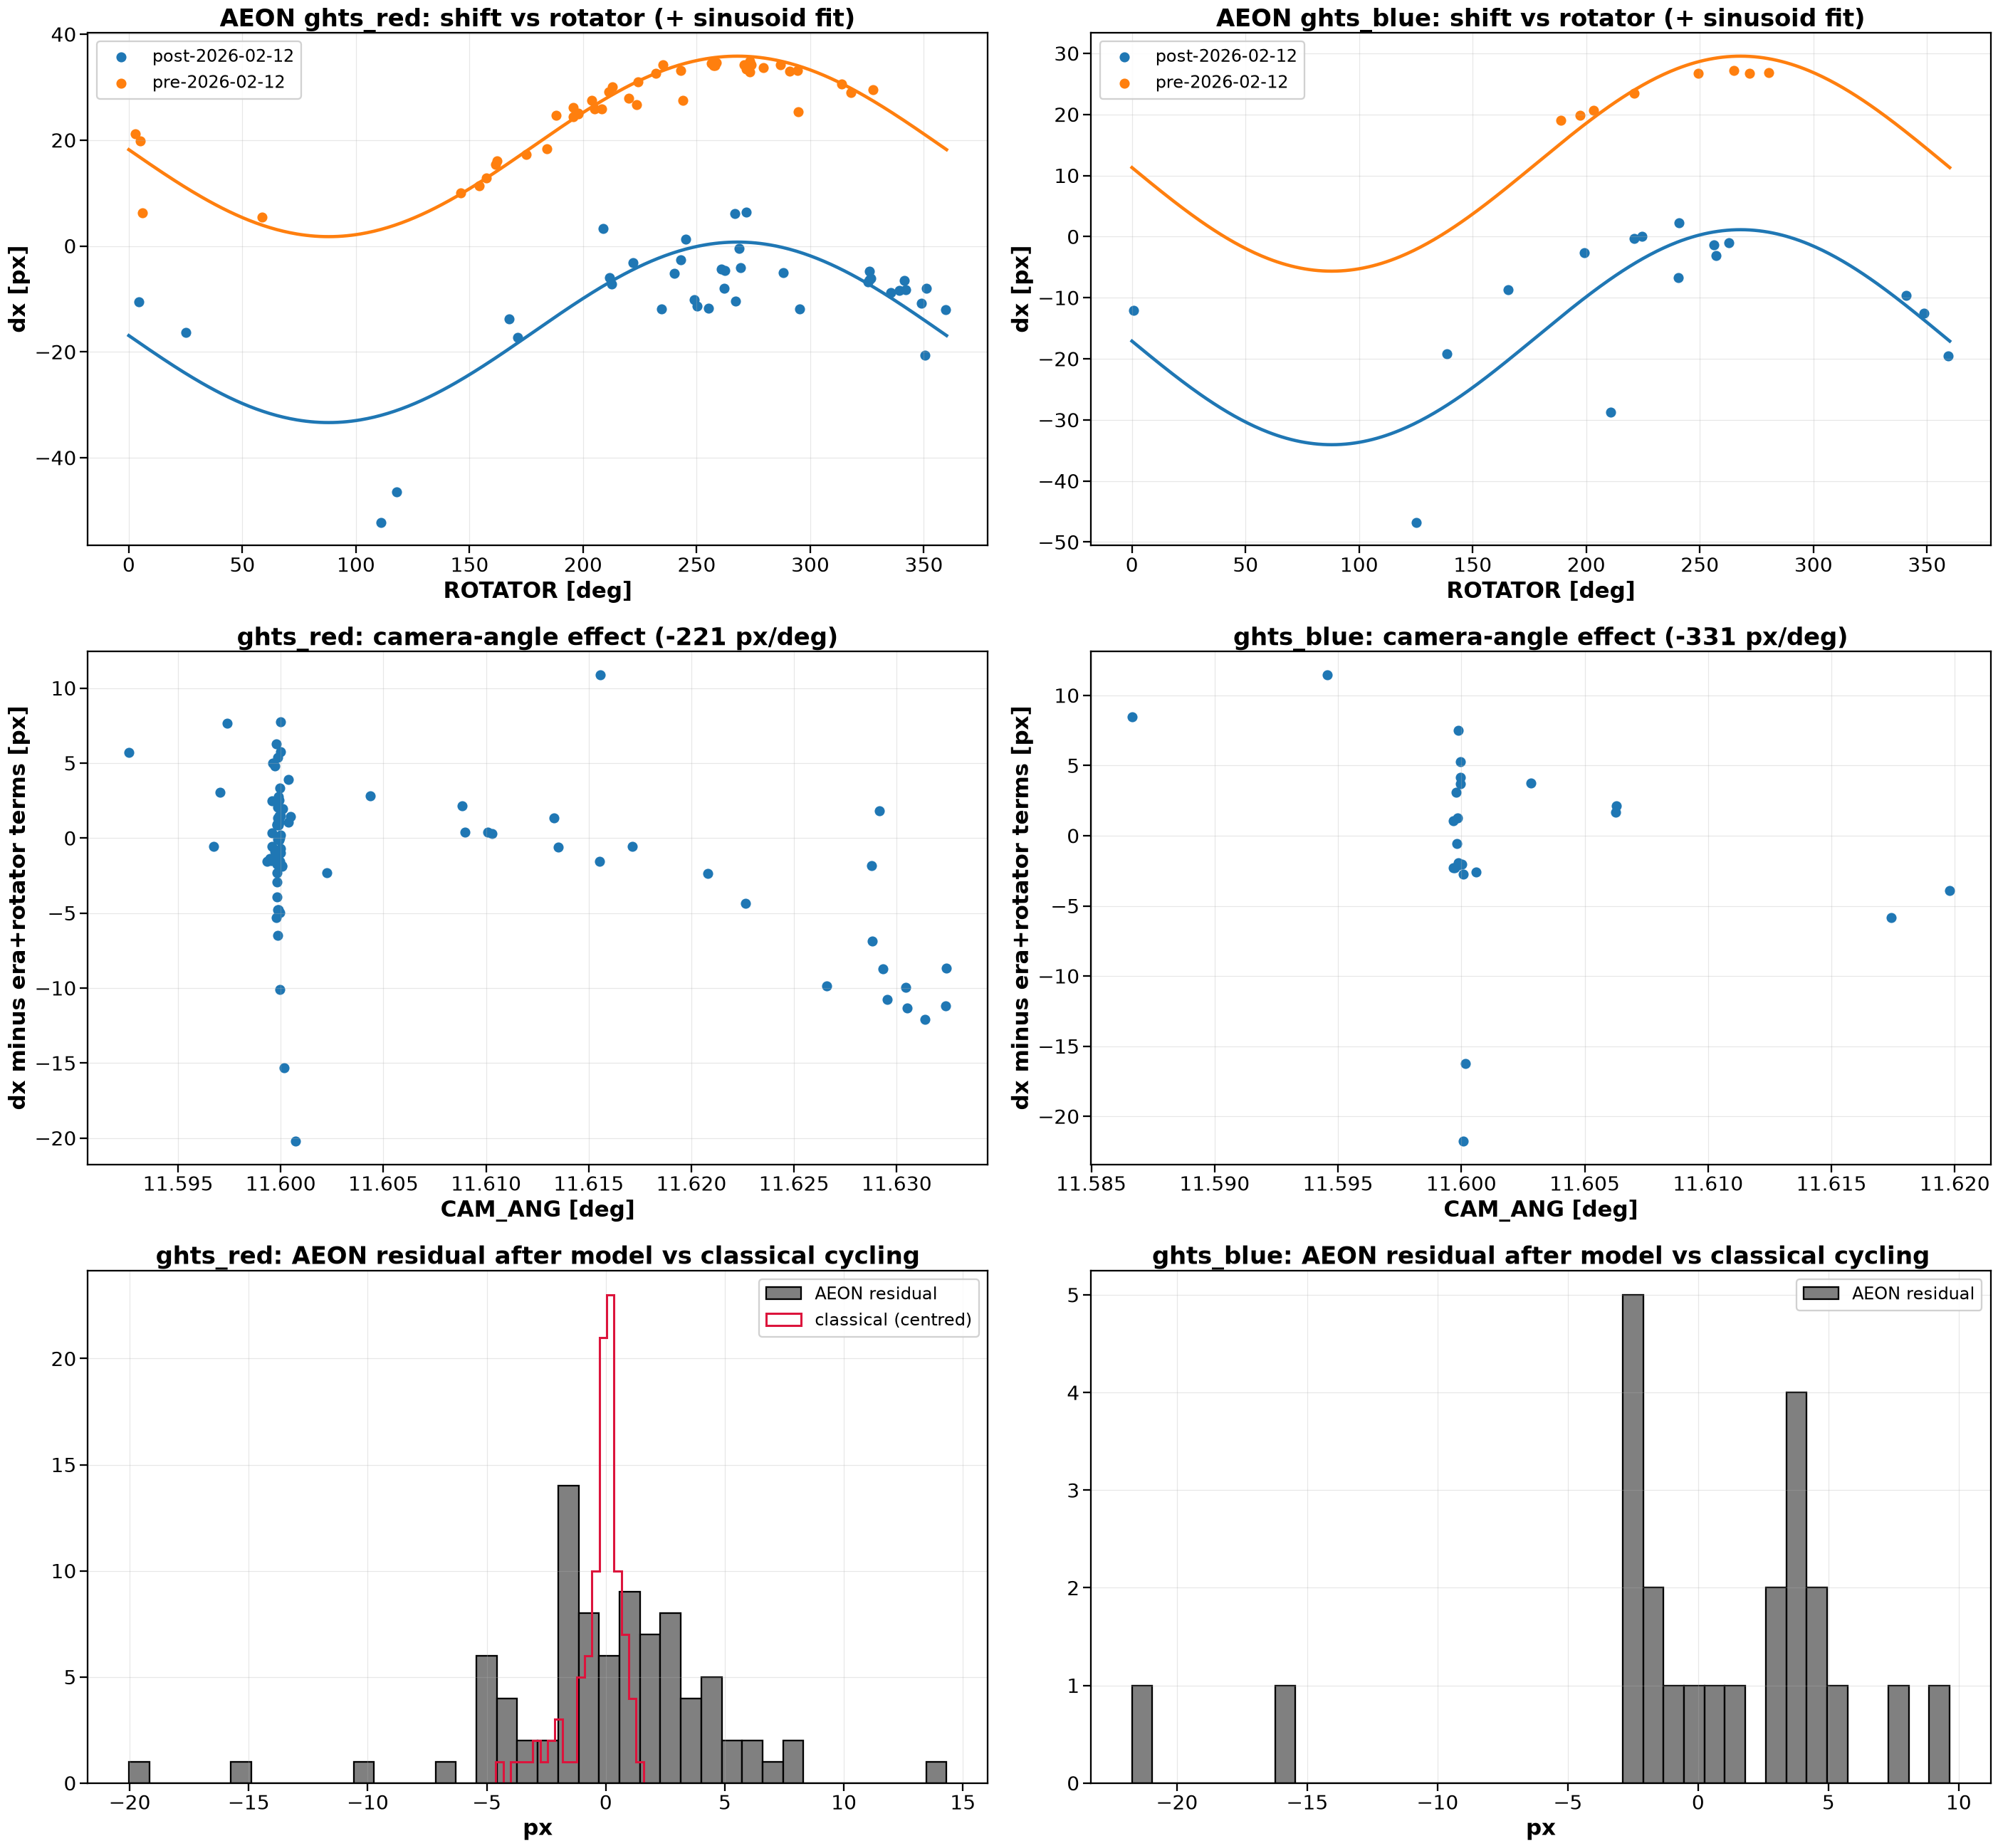

In [21]:
fig, ax = plt.subplots(3, 2, figsize=(26, 24))
rr = np.linspace(0, 360, 361)
for row, cam in enumerate(["ghts_red", "ghts_blue"]):
    g = blk[(blk.set == "aeon") & (blk.instr == cam)]
    beta, res = fits_out[(cam, "rotator + cam_ang")]
    for era, ge in g.groupby("era"):
        ax[0, row].scatter(ge.rotator, ge.dx, s=60, label=era)
        off = beta[f"offset[{era}]"]
        ax[0, row].plot(rr, off + beta.sin_rot * np.sin(np.deg2rad(rr)) + beta.cos_rot * np.cos(np.deg2rad(rr)), lw=3)
    ax[0, row].set(xlabel="ROTATOR [deg]", ylabel="dx [px]", title=f"AEON {cam}: shift vs rotator (+ sinusoid fit)")
    ax[0, row].legend()

    # partial residual for cam_ang: remove everything except the cam_ang term
    part = res + beta.cam_ang * (g.cam_ang.values - 11.6)
    ax[1, row].scatter(g.cam_ang, part, s=60)
    ax[1, row].set(xlabel="CAM_ANG [deg]", ylabel="dx minus era+rotator terms [px]",
                   title=f"{cam}: camera-angle effect ({beta.cam_ang:+.0f} px/deg)")

    ax[2, row].hist(res, bins=40, color="grey", edgecolor="k", label="AEON residual")
    c = blk[(blk.set == "classical")].dx
    if cam == "ghts_red":
        ax[2, row].hist(c - c.median(), bins=20, histtype="step", lw=2, color="crimson", label="classical (centred)")
    ax[2, row].set(xlabel="px", title=f"{cam}: AEON residual after model vs classical cycling")
    ax[2, row].legend()
plt.tight_layout()
plt.show()


### Shift vs rotator angle and camera angle, coloured by date

One point per AEON block (median `dx` of its arcs). Colour shows the observation date, so slow drifts and the Feb 2026 jump appear as colour bands rather than scatter. The classical night is left out: its rotator is fixed at 360°, and its October date would compress the colour scale.

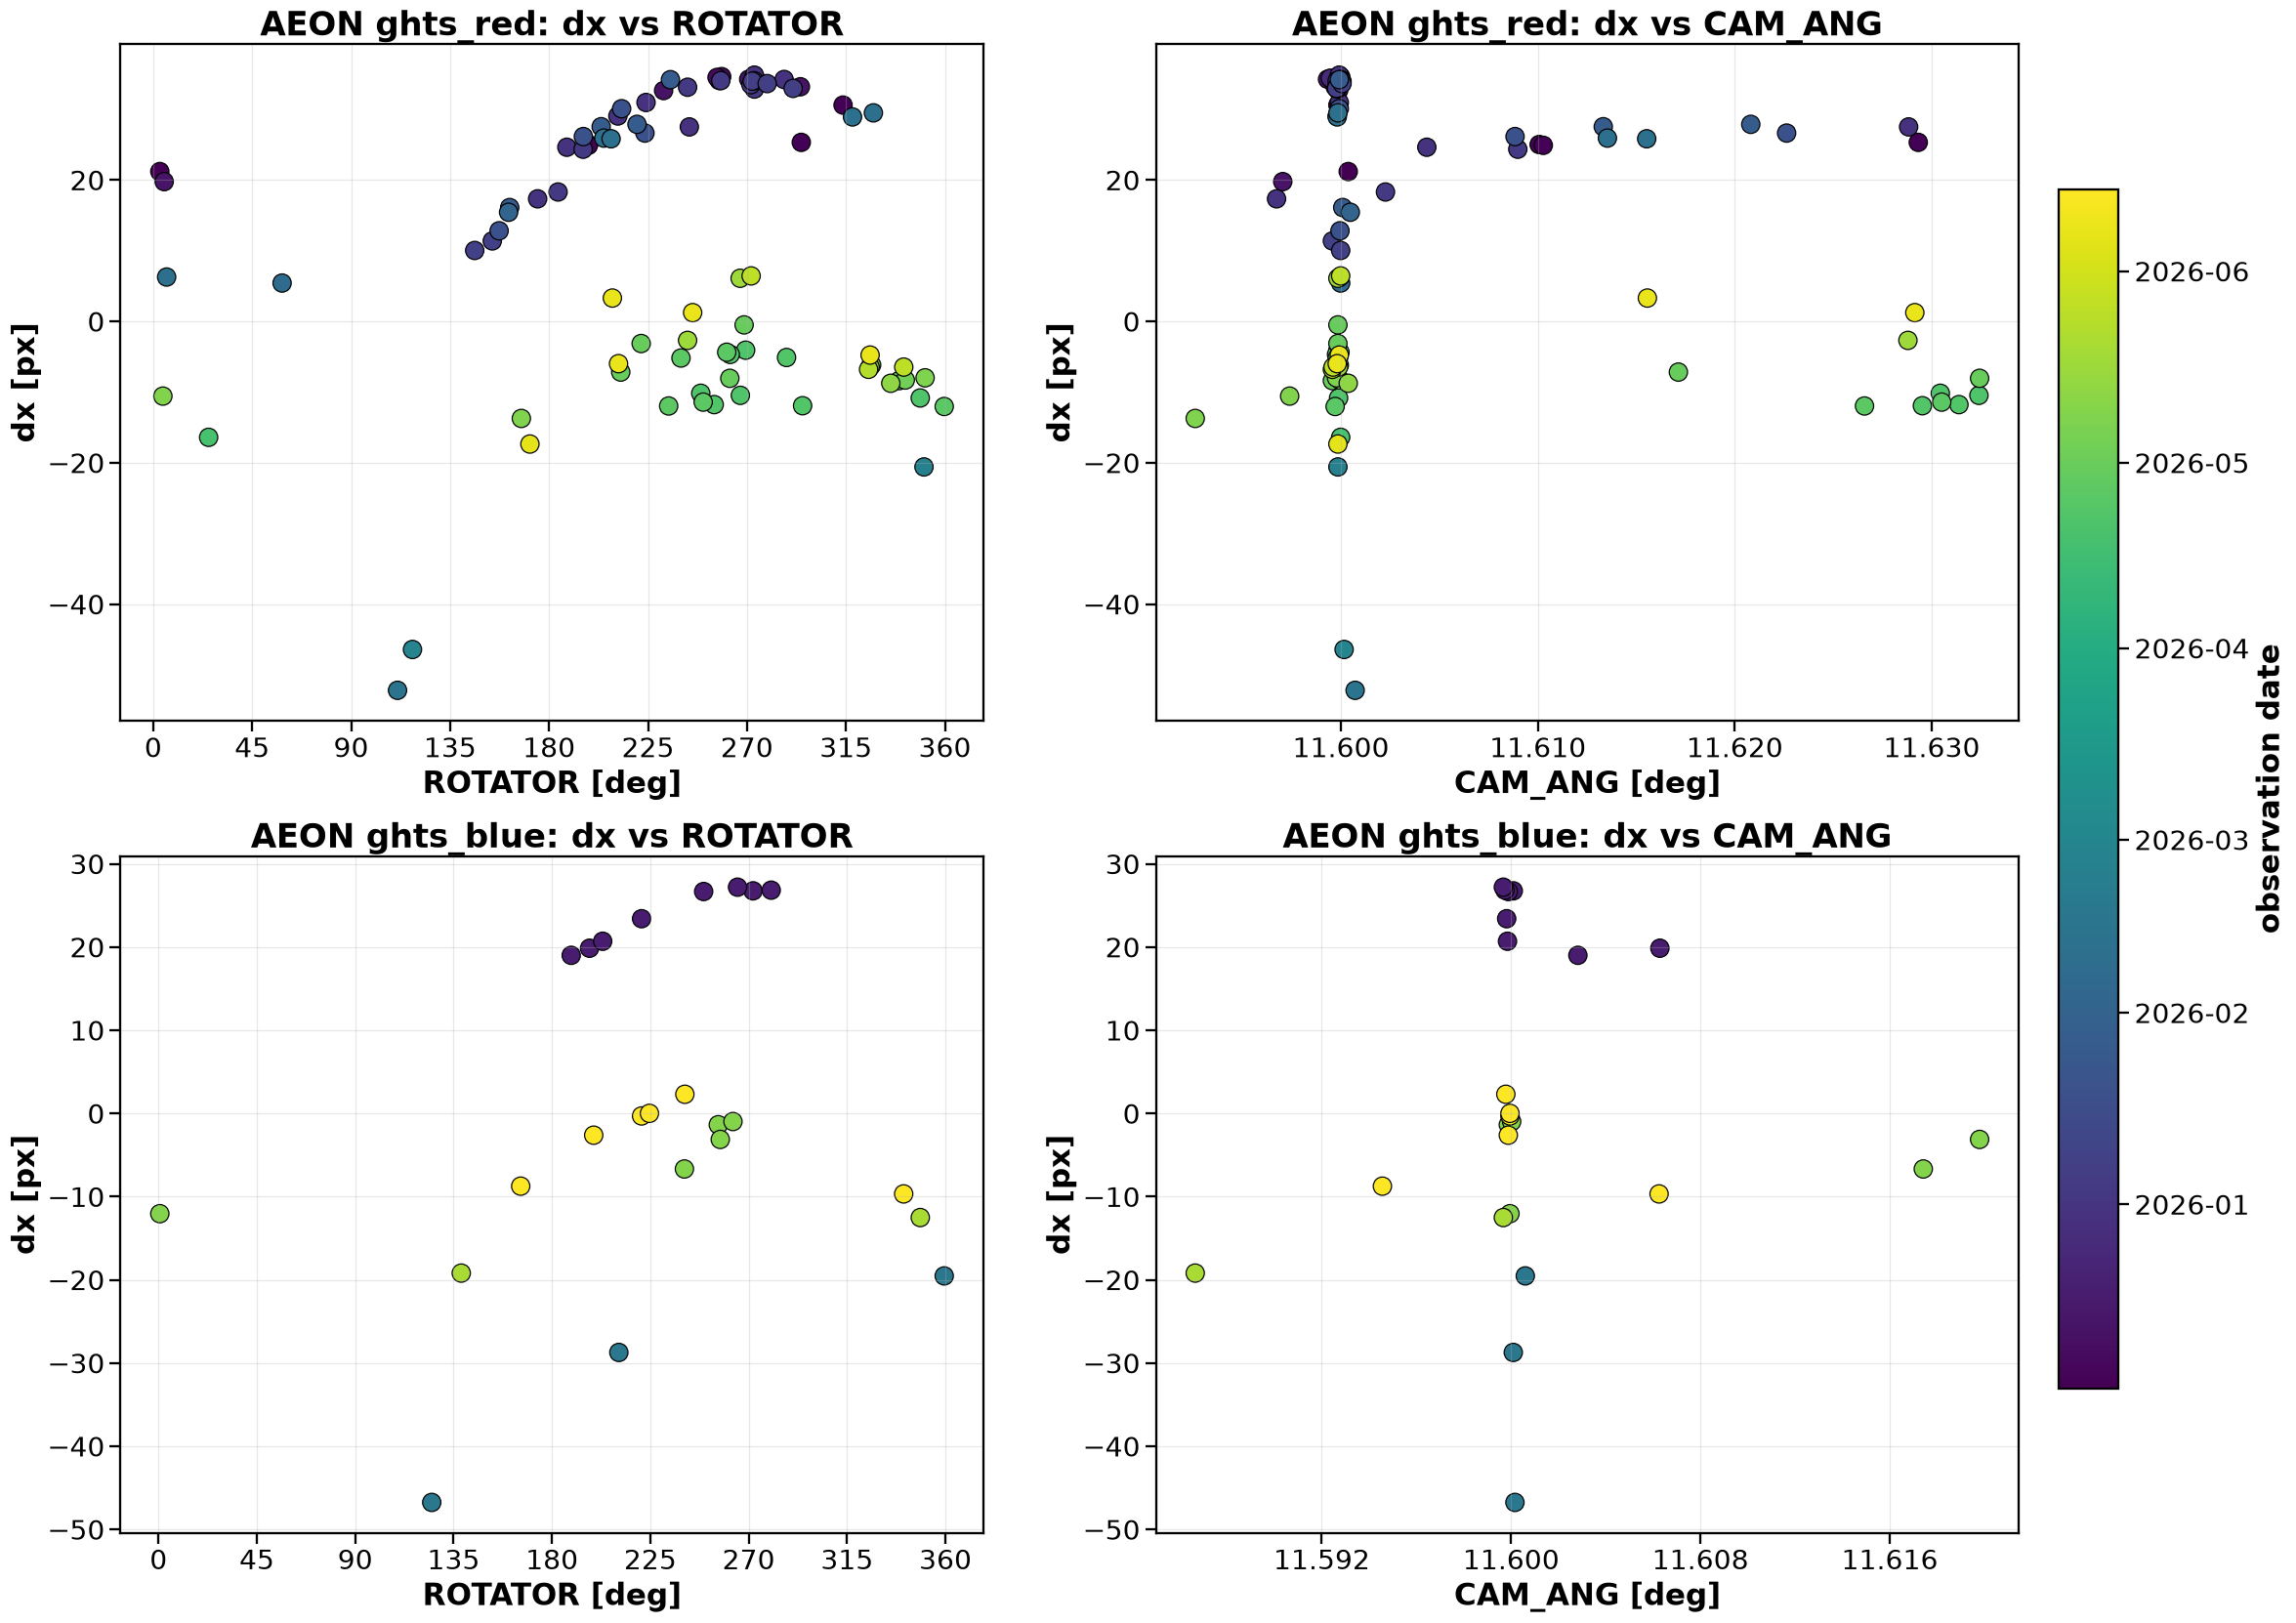

In [22]:
import matplotlib.dates as mdates

aeon_blk = blk[blk.set == "aeon"]
tnum = mdates.date2num(aeon_blk.t)
norm = plt.Normalize(tnum.min(), tnum.max())   # same colour scale for every panel
cmap = "viridis"

fig, ax = plt.subplots(2, 2, figsize=(24, 18))
for row, cam in enumerate(["ghts_red", "ghts_blue"]):
    g = aeon_blk[aeon_blk.instr == cam]
    c = mdates.date2num(g.t)
    for col, (p, label) in enumerate([("rotator", "ROTATOR [deg]"), ("cam_ang", "CAM_ANG [deg]")]):
        sc = ax[row, col].scatter(g[p], g.dx, c=c, cmap=cmap, norm=norm, s=150,
                                  edgecolor="k", linewidth=0.8)
        ax[row, col].set(xlabel=label, ylabel="dx [px]", title=f"AEON {cam}: dx vs {p.upper()}")
    ax[row, 0].set_xticks(np.arange(0, 361, 45))
    ax[row, 1].xaxis.set_major_locator(plt.MaxNLocator(5))   # avoid overlapping CAM_ANG labels
    ax[row, 1].xaxis.set_major_formatter(plt.FormatStrFormatter("%.3f"))

cbar = fig.colorbar(sc, ax=ax, orientation="vertical", fraction=0.03, pad=0.02)
cbar.ax.yaxis.set_major_locator(mdates.MonthLocator())
cbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
cbar.set_label("observation date", fontsize=20, fontweight="bold")
cbar.ax.tick_params(labelsize=18)
plt.show()


### Timeline: has the shift got worse over time?

Each point is one block (median `dx` of its back-to-back arcs), plotted against observation date. AEON red, AEON blue, and the classical night are shown together.
- **Marker shape** shows the camera. **Colour** shows the rotator angle, with a cyclic colour map so 0° and 360° get the same colour. That way, scatter driven by the rotator can be told apart from a real drift over time.
- **Dashed line:** the Feb 2026 jump.
- **Zero points:** red `dx` is relative to the classical template; blue `dx` is relative to the AEON-blue template. Only *changes* within each camera are meaningful, not the offset between the two cameras.

"Getting worse" could mean the typical position drifting, or the spread growing. The table below the plot gives both for each month: the median and the robust spread of `dx`.

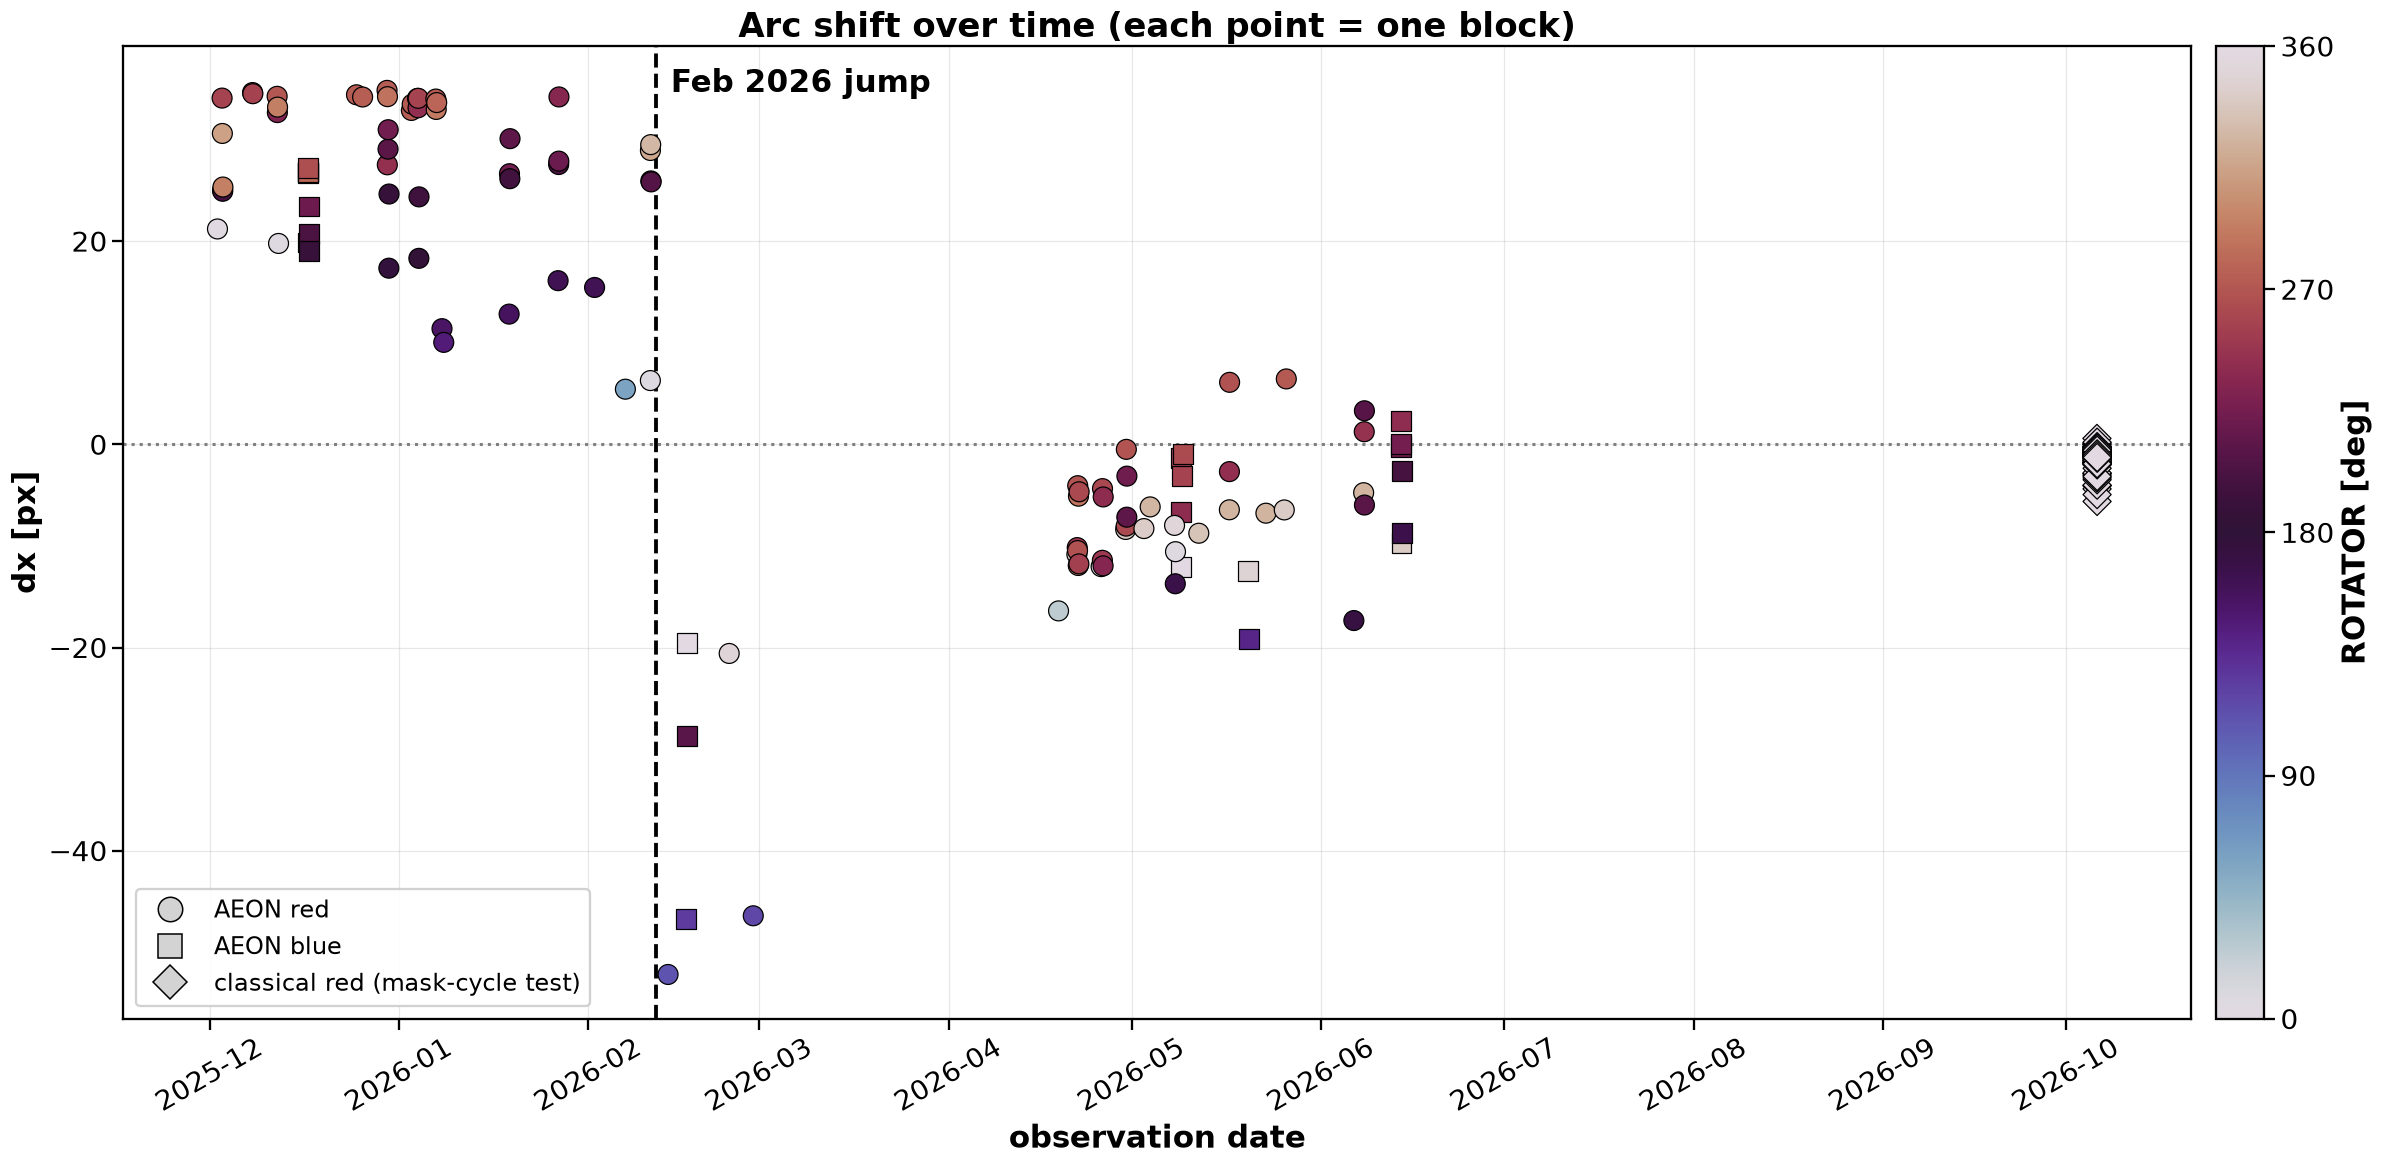

                             n_blocks  median  robust_spread    min    max
set       instr     month                                                 
aeon      ghts_blue 2025-12         8   25.05           2.93  19.01  27.20
                    2026-02         3  -28.72          13.64 -46.75 -19.52
                    2026-05         7   -6.67           7.97 -19.18  -0.97
                    2026-06         6   -1.45           3.88  -9.67   2.31
          ghts_red  2025-12        21   30.97           5.12  17.34  34.85
                    2026-01        20   28.99           6.88  10.04  34.20
                    2026-02        10   10.86          24.56 -52.18  29.50
                    2026-04        19   -8.38           5.03 -16.39  -0.49
                    2026-05        12   -6.61           2.82 -13.72   6.44
                    2026-06         5   -4.76           8.90 -17.34   3.31
classical ghts_red  2026-10       101   -1.00           0.60  -5.62   0.58


In [23]:
markers = {("aeon", "ghts_red"): ("o", "AEON red"), ("aeon", "ghts_blue"): ("s", "AEON blue"),
           ("classical", "ghts_red"): ("D", "classical red (mask-cycle test)")}

fig, ax = plt.subplots(figsize=(24, 11))
for (s, cam), g in blk.groupby(["set", "instr"]):
    mk, label = markers[(s, cam)]
    sc = ax.scatter(g.t, g.dx, c=g.rotator, cmap="twilight", vmin=0, vmax=360,
                    marker=mk, s=170, edgecolor="k", linewidth=0.8, label=label, zorder=3)
ax.axvline(ERA_SPLIT, color="k", ls="--", lw=2.5, zorder=2)
ax.annotate("Feb 2026 jump", xy=(ERA_SPLIT, ax.get_ylim()[1]), xytext=(10, -30),
            textcoords="offset points", fontsize=20, fontweight="bold")
ax.axhline(0, color="grey", ls=":", lw=2)
ax.set(xlabel="observation date", ylabel="dx [px]", title="Arc shift over time (each point = one block)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.tick_params(axis="x", labelrotation=30)

# legend with neutral grey markers (point colours encode rotator, not camera)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker=mk, ls="", ms=16, mfc="lightgrey", mec="k", label=label)
                   for mk, label in markers.values()], loc="lower left")
cbar = fig.colorbar(sc, ax=ax, pad=0.01)
cbar.set_label("ROTATOR [deg]", fontsize=20, fontweight="bold")
cbar.set_ticks(np.arange(0, 361, 90))
plt.tight_layout()
plt.show()

# month-by-month: typical position and spread (robust sigma) per camera
monthly = (blk.assign(month=blk.t.dt.to_period("M"))
              .groupby(["set", "instr", "month"])
              .dx.agg(n_blocks="size", median="median", robust_spread=mad_, min="min", max="max"))
print(monthly.round(2).to_string())


## Q3: Can the shift identify where the mask was cycled? Which headers help?

- **From the spectra:** without a cycle, consecutive arcs repeat to about 0.01–0.1 px (classical 10 s pairs, and arcs within an AEON block). Across a cycle, they almost always move by more than 0.05 px. So a step above about 5× the within-block noise marks a cycle (or a pointing change).
- **From headers:** there is no keyword that records the slit mask being moved. Proxies:
  - a gap > 20 s between arcs, or a change in `OBJECT`, `BLOCK_ID`, or `REQNUM` (AEON);
  - a change in `ROTATOR`;
  - in AEON, a change in `CAM_ANG`. The camera articulation is re-commanded on each configuration change, and its encoder reading lands at slightly different values (11.600 vs 11.63°).

The cell below quantifies how well "new block" (a header/time rule) agrees with "spectrum moved" (a shift rule), and which header values correlate with the block-to-block step.

In [24]:
from scipy.stats import spearmanr

# within-block noise (no cycle) vs between-block steps
wb = ok2.groupby("block").dx.apply(lambda v: v - v.median()).abs()
noise_nc = 1.4826 * np.median(wb[wb > 0]) if (wb > 0).any() else np.nan
print(f"within-block (no-cycle) scatter ~ {noise_nc:.3f} px")
for (s, cam), g in blk.groupby(["set", "instr"]):
    st_ = g.step.dropna().abs()
    if len(st_):
        thr = max(5 * noise_nc, 0.05)
        print(f"{s:9s} {cam:9s}: {int((st_ > thr).sum())}/{len(st_)} block-to-block steps exceed {thr:.2f} px "
              f"(median |step| {st_.median():.2f} px)")

# which header values track the shift? (AEON, per camera, Spearman rank correlation with dx)
params = ["rotator", "mount_el", "mount_az", "cam_ang", "grt_ang", "cam_temp", "col_temp", "env_temp", "exptime"]
rows = []
for cam in ["ghts_red", "ghts_blue"]:
    for era in blk.era.unique():
        g = blk[(blk.set == "aeon") & (blk.instr == cam) & (blk.era == era)]
        if len(g) < 8:
            continue
        for p in params:
            if g[p].nunique() > 2:
                rho, pv = spearmanr(g[p], g.dx)
                rows.append({"camera": cam, "era": era, "param": p, "N": len(g), "rho": rho, "p": pv})
corr_tab = pd.DataFrame(rows)
print("\nSpearman correlation of block shift with header values (|rho| > 0.3 and p < 0.01 shown):")
print(corr_tab[(corr_tab.rho.abs() > 0.3) & (corr_tab.p < 0.01)].sort_values(["camera", "era", "p"])
      .round(3).to_string(index=False))


within-block (no-cycle) scatter ~ 0.037 px
aeon      ghts_blue: 18/19 block-to-block steps exceed 0.19 px (median |step| 5.37 px)
aeon      ghts_red : 52/55 block-to-block steps exceed 0.19 px (median |step| 5.17 px)
classical ghts_red : 76/100 block-to-block steps exceed 0.19 px (median |step| 0.57 px)

Spearman correlation of block shift with header values (|rho| > 0.3 and p < 0.01 shown):
   camera             era    param  N    rho     p
ghts_blue post-2026-02-12 env_temp 16 -0.885 0.000
ghts_blue post-2026-02-12 col_temp 16 -0.782 0.000
ghts_blue post-2026-02-12 cam_temp 16 -0.645 0.007
ghts_blue  pre-2026-02-12  rotator  8  0.929 0.001
ghts_blue  pre-2026-02-12 cam_temp  8  0.880 0.004
 ghts_red  pre-2026-02-12  rotator 48  0.775 0.000
 ghts_red  pre-2026-02-12 mount_az 48  0.491 0.000


### Camera angle moves the spectrum even *without* a mask cycle

Some AEON blocks contain a jump *within* the ~11 s triplet: no mask cycle, and the rotator changes by only about 0.1°. In every such case the `CAM_ANG` encoder reading also changed. The ratio shift / ΔCAM_ANG gives the camera-angle sensitivity directly, without needing any model.

In [25]:
jumps = []
for b, g in ok2.groupby("block"):
    g = g.sort_values("date_obs")
    for p, c in zip(g.iloc[:-1].itertuples(), g.iloc[1:].itertuples()):
        if abs(c.dx - p.dx) > 0.5:
            jumps.append({"pair": f"{p.bn[:4]}->{c.bn[:4]}", "instr": c.instr, "night": c.night,
                          "dt_s": (c.date_obs - p.date_obs).total_seconds(),
                          "d_rotator": c.rotator - p.rotator, "d_cam_ang": c.cam_ang - p.cam_ang,
                          "d_dx": c.dx - p.dx})
jumps = pd.DataFrame(jumps)
jumps["px_per_deg"] = np.where(jumps.d_cam_ang.abs() > 0.002, jumps.d_dx / jumps.d_cam_ang, np.nan)
print(jumps.round(4).to_string(index=False))
# jumps with no CAM_ANG change (px_per_deg = NaN) are small and involve a first, still-warming-up arc
CAM_SENS = jumps.px_per_deg.median()
print(f"\nCamera-angle sensitivity from within-block jumps: {CAM_SENS:.0f} px/deg "
      f"(=> 0.01 deg of CAM_ANG ~ {abs(CAM_SENS) * 0.01:.1f} px)")


      pair     instr      night   dt_s  d_rotator  d_cam_ang    d_dx  px_per_deg
0217->0218 ghts_blue 2026-06-13 14.866        0.1     0.0142 -3.0685   -216.4702
0242->0243 ghts_blue 2026-06-13 15.008        0.1     0.0057 -1.2430   -217.8854
0256->0257  ghts_red 2025-12-29 11.312        0.1     0.0288 -6.4060   -222.6635
0284->0285  ghts_red 2026-06-07 11.289        0.1    -0.0000 -0.7066         NaN

Camera-angle sensitivity from within-block jumps: -218 px/deg (=> 0.01 deg of CAM_ANG ~ 2.2 px)


### Within-night scatter after removing the camera-angle and rotator terms

To compare AEON with the classical test like for like:
1. Remove the camera-angle term, using the sensitivity measured above.
2. Fit a rotator sinusoid with **one offset per night**. This absorbs slow drifts and the era jump.
3. The remaining scatter *within a night* is what's left for the mask cycle (plus anything not modelled). The classical night measures the mask-cycle-only scatter directly, so the two can be compared.

                           sample  blocks  nights  rot_amp_px  rot_phase_deg  within_night_std  within_night_robust
                   AEON ghts_blue      24       5       11.57         175.34              3.50                 1.49
                    AEON ghts_red      73      18       14.87        -175.63              2.79                 1.70
classical ghts_red (cycling only)     101       1         NaN            NaN              1.11                 0.60


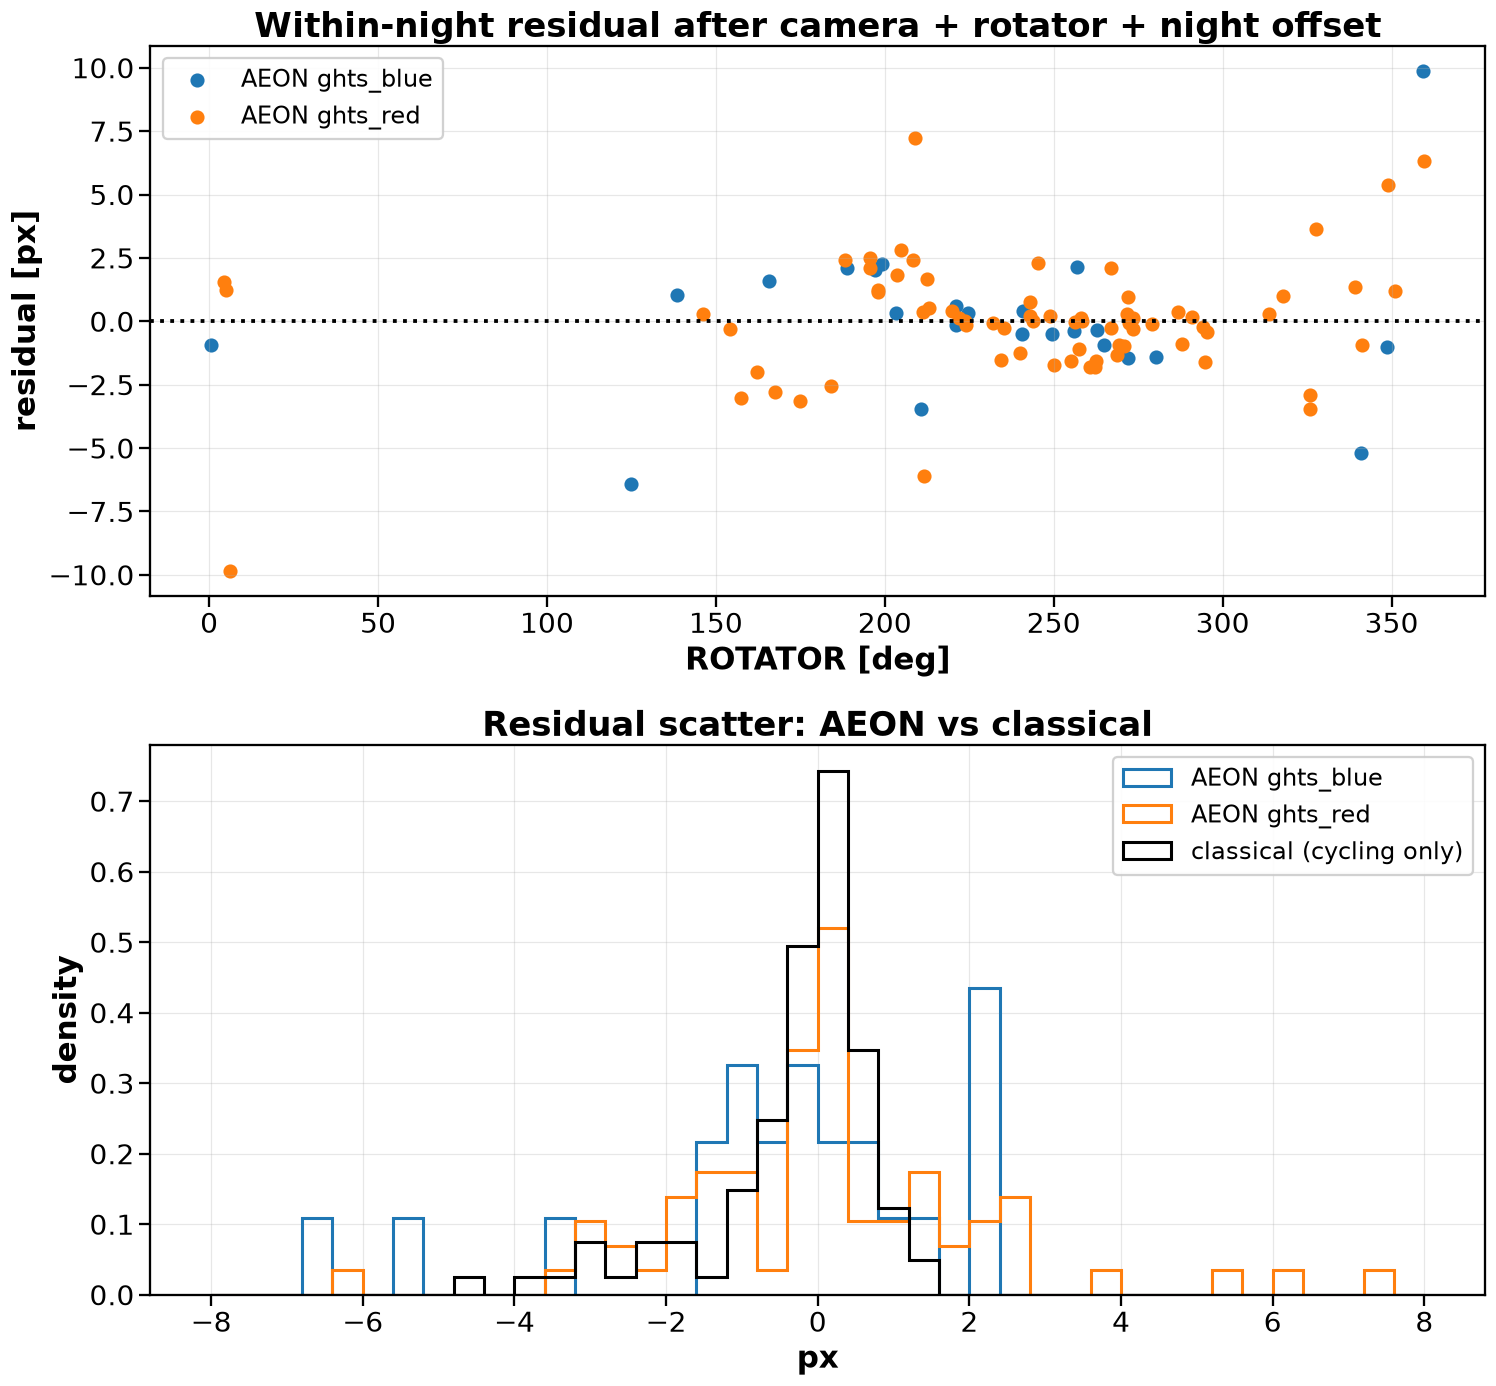

In [26]:
a2 = blk[blk.set == "aeon"].copy()
a2["dx_cam"] = a2.dx - CAM_SENS * (a2.cam_ang - 11.6)

def fit_per_night(g):
    r = np.deg2rad(g.rotator.values)
    nights = sorted(g.night.unique())
    X = np.column_stack([(g.night == n).values.astype(float) for n in nights] + [np.sin(r), np.cos(r)])
    beta, *_ = np.linalg.lstsq(X, g.dx_cam.values, rcond=None)
    return beta[-2:], g.dx_cam.values - X @ beta

summary_rows = []
for cam, g in a2.groupby("instr"):
    # only nights with >= 2 blocks constrain the rotator term / within-night scatter
    multi = g.groupby("night").night.transform("size") >= 2
    (bs, bc), res = fit_per_night(g[multi])
    a2.loc[g[multi].index, "res_night"] = res
    n_dof = multi.sum() - g[multi].night.nunique() - 2
    summary_rows.append({"sample": f"AEON {cam}", "blocks": int(multi.sum()), "nights": g[multi].night.nunique(),
                         "rot_amp_px": np.hypot(bs, bc), "rot_phase_deg": np.degrees(np.arctan2(bc, bs)),
                         "within_night_std": np.sqrt(np.sum(res**2) / max(n_dof, 1)),
                         "within_night_robust": mad_(res)})
c = blk[blk.set == "classical"].dx
summary_rows.append({"sample": "classical ghts_red (cycling only)", "blocks": len(c), "nights": 1,
                     "rot_amp_px": np.nan, "rot_phase_deg": np.nan,
                     "within_night_std": c.std(), "within_night_robust": mad_(c)})
print(pd.DataFrame(summary_rows).round(2).to_string(index=False))

fig, ax = plt.subplots(2, 1, figsize=(14, 13))
for cam, g in a2.dropna(subset=["res_night"]).groupby("instr"):
    ax[0].scatter(g.rotator, g.res_night, s=60, label=f"AEON {cam}")
ax[0].axhline(0, color="k", ls=":")
ax[0].set(xlabel="ROTATOR [deg]", ylabel="residual [px]", title="Within-night residual after camera + rotator + night offset")
ax[0].legend()
bins = np.linspace(-8, 8, 41)
for cam, g in a2.dropna(subset=["res_night"]).groupby("instr"):
    ax[1].hist(g.res_night, bins=bins, histtype="step", lw=2, density=True, label=f"AEON {cam}")
ax[1].hist(c - c.median(), bins=bins, histtype="step", lw=2, density=True, color="k", label="classical (cycling only)")
ax[1].set(xlabel="px", ylabel="density", title="Residual scatter: AEON vs classical")
ax[1].legend()
plt.tight_layout()
plt.show()


## Summary (see the cell outputs above for the exact numbers)

**Q1: Do classical and AEON show similar shifts? No.** AEON shifts are 10–30× larger.
- Classical: positions spread by about 0.6 px robust (≤ 6 px total), with the one-sided skew found in Part 1.
- AEON (red and blue): positions span about 90 px (−52 to +35 px), and same-night block-to-block steps have a typical size of about 5 px.
- Without a cycle, both are equally stable: about 0.02 px within an AEON triplet, about 0.01 px for classical back-to-back pairs.

**Q2: Is it the mask cycling? Only partly.** At least four separate effects contribute in AEON:
1. **Rotator angle:** a sinusoid with an amplitude of about 15–19 px, nearly the same for both cameras, dominated by the sin(rotator) term. The classical test had the rotator fixed, so it could not see this. It points to a gravity-dependent effect: instrument flexure, or the mask settling differently in its holder depending on the gravity direction. AEON cycles the mask before every block, so the AEON data alone *can't* tell flexure from gravity-dependent mask seating.
2. **Camera articulation angle (`CAM_ANG`):** about −220 px/deg, measured directly from within-block jumps with no cycle. The encoder lands at either about 11.600° or about 11.63° (0.03° ≈ 6–7 px). This is **not** the mask.
3. **Slow, night-to-night offsets,** including a large step (about 35 px) between 11 and 14 Feb 2026 in *both* cameras. That looks like an instrument intervention (maintenance, mask or slit reinstall, rotator re-zero) and should be checked in the SOAR logs.
4. **What's left: the mask cycle itself.** After removing items 1–3, the within-night scatter is about 1.5–1.7 px robust (std about 3 px). The classical cycling scatter is 0.6 px robust (std 1.1 px), so the residual is about 2.5× larger. Mask repositioning probably accounts for part of it; the rest is unmodelled (for example, the rotator dependence may not be a pure sinusoid).

There is also a **stretch** of 0.3–2.4 px per 1000 px in AEON red relative to the classical template. It correlates with camera and collimator temperature (the AEON nights were 14–22 °C; the classical night was about 11.7 °C), so it is a thermal change in dispersion. A single shift is therefore not a perfect correction across the whole detector for AEON arcs.

**Q3: Can we identify where the mask was cycled?**
- From the spectra: a step above about 0.2 px between consecutive arcs (5× the no-cycle noise) flags a change. It *can't* distinguish a mask cycle from a camera-angle change or a rotator move.
- From headers: no keyword records a slit-mask move. Useful proxies are a time gap > 20 s, a change in `OBJECT`/`BLOCK_ID`, a `ROTATOR` change, and especially **any change in `CAM_ANG`**, which predicts the shift by itself.

**Q4: Rotator angle?** Yes, it is the single largest predictor (Spearman ρ ≈ 0.78 within the pre-Feb era). See the sinusoid fits above.

**Q5: Other ideas / next tests**
1. **Separate flexure from mask seating:** on a classical night, step the rotator through 0–360° *without* cycling the mask (flexure only). Then, at several fixed rotator angles, cycle the mask about 10 times (mask seating only).
2. **Camera angle:** command `CAM_ANG` to the same target repeatedly and record the encoder value and arc shift. Ask the instrument team why it lands on two values (11.600 vs 11.63°).
3. **Look up the 11–14 Feb 2026 event** in the SOAR engineering logs.
4. **Correction model:** predict the arc position from `ROTATOR` + `CAM_ANG` (+ temperature for the stretch). Use the arc taken *with* each science block for the final zero point, since about 1.5–3 px of within-night residual stays unpredictable.
5. **Lamp warm-up:** the first arc of each AEON triplet correlates worse (about 0.55 vs 0.75–0.93) and drifts by about 0.1–0.3 px. The Hg lines are still brightening. Prefer the 2nd or 3rd arc of a triplet for calibration.
6. **Saturation:** AEON blue arcs reach 65535 ADU and AEON red reach about 55k. Saturated, flat-topped lines bias centroids, so a shorter exposure would help.

# Part 3: Reference lamp spectrum with a known wavelength solution

**Source:** the SOAR `goodman_lamps` repository (https://github.com/soar-telescope/goodman_lamps, BSD-3-Clause). The package's own plotting code needs the Goodman pipeline, so instead the data files were copied into `reference_lamps/`. The commit is recorded in `SOURCE.txt`.

`goodman_comp_400M1_HgArNe.fits` is a **reduced Goodman arc** (5 combined exposures, taken 2017-12-18) that stores:
- the 1D spectrum (4060 px, **unbinned 1×1**);
- its wavelength solution: a 3rd-order Chebyshev polynomial in pixel (`GSP_FUNC`, `GSP_C000`–`GSP_C003`), covering about 3016–7038 Å;
- the identified lines: pixel `GSP_Pnnn` and wavelength `GSP_Annn`.

It was taken with the same red-camera CCD as our arcs (serial `10282-14-01`), at `CAM_ANG` 11.567°.

**Pixel mapping to our arcs:** the reference starts at unbinned detector column 51 (`GSP_TRIM`). Our 2×2-binned arcs start at binned column 26 (`TRIMSEC`), which covers unbinned columns 51–52. So binned pixel `j` covers unbinned pixels `2j` and `2j+1` of the reference, and its centre is at `2j + 0.5`.

**Caveat:** this reference has only been verified against the **red** camera. The blue camera's CCD serial isn't in its headers, so any blue comparison needs its own check.

In [27]:
import re
from astropy.modeling import models

REF_DIR = "reference_lamps"
ref_hdr = fits.getheader(os.path.join(REF_DIR, "goodman_comp_400M1_HgArNe.fits"))
ref_flux_1x1 = fits.getdata(os.path.join(REF_DIR, "goodman_comp_400M1_HgArNe.fits")).astype(float)

# wavelength solution: Chebyshev1D with the default (identity) domain, evaluated on the unbinned pixel index
order = ref_hdr["GSP_ORDR"]
wsol_1x1 = models.Chebyshev1D(order, **{f"c{i}": ref_hdr[f"GSP_C{i:03d}"] for i in range(order + 1)})

# identified lines stored in the header
pkeys = sorted(k for k in ref_hdr if re.fullmatch(r"GSP_P\d{3}", k))
ref_lines = pd.DataFrame({"pix_1x1": [ref_hdr[k] for k in pkeys],
                          "wavelength": [ref_hdr[k.replace("_P", "_A")] for k in pkeys]})
ref_lines["fit_resid_A"] = ref_lines.wavelength - wsol_1x1(ref_lines.pix_1x1)
ref_lines["pix_2x2"] = (ref_lines.pix_1x1 - 0.5) / 2          # position on our binned grid

print(f"Reference: {ref_hdr['GSP_FNAM']}  ({ref_hdr['DATE-OBS'][:10]}, {ref_hdr['ROI']}, "
      f"CAM_ANG={ref_hdr['CAM_ANG']}, CCD {ref_hdr['PG1_2']})")
print(f"Wavelength range: {wsol_1x1(0):.1f} - {wsol_1x1(len(ref_flux_1x1) - 1):.1f} A, "
      f"dispersion ~{np.gradient(wsol_1x1(np.arange(len(ref_flux_1x1)))).mean():.3f} A/px unbinned")
print(f"{len(ref_lines)} identified lines, solution rms = {ref_lines.fit_resid_A.std():.3f} A")

# bin the reference 2x onto our grid (sum pixel pairs) and give each binned pixel its wavelength
n2 = len(ref_flux_1x1) // 2
ref_flux_2x2 = ref_flux_1x1[:2 * n2].reshape(n2, 2).sum(axis=1)
ref_wave_2x2 = wsol_1x1(2 * np.arange(n2) + 0.5)
print(f"Binned reference: {n2} px (our arcs: {len(templates['ghts_red'])} px), "
      f"~{np.gradient(ref_wave_2x2).mean():.3f} A/px")

# NIST strong-line lists (air wavelengths) for Hg, Ar, Ne
def read_nist(path):
    rows = []
    for line in open(path):
        parts = [p.strip() for p in line.split(",")]
        if len(parts) >= 3:
            try:
                rows.append({"wavelength": float(parts[1]), "ion": parts[2], "rel_int": parts[0]})
            except ValueError:
                pass
    return pd.DataFrame(rows)

nist = pd.concat([read_nist(os.path.join(REF_DIR, "nist", f"nist_air_strong_lines_{el}.txt"))
                  for el in ["Hg", "Ar", "Ne"]], ignore_index=True)
print(f"NIST lines loaded: {len(nist)} ({nist.ion.value_counts().to_dict()})")
ref_lines.round(3)


Reference: goodman_comp_400M1_HgArNe.fits  (2017-12-18, Spectroscopic 1x1, CAM_ANG=11.567155, CCD 10282-14-01)
Wavelength range: 3015.8 - 7038.5 A, dispersion ~0.991 A/px unbinned
23 identified lines, solution rms = 0.127 A
Binned reference: 2030 px (our arcs: 2030 px), ~1.982 A/px
NIST lines loaded: 701 ({'Ne I': 227, 'Ne II': 165, 'Ar II': 137, 'Ar I': 122, 'Hg II': 25, 'Hg I': 25})


,pix_1x1,wavelength,fit_resid_A,pix_2x2
0,638.109,3650.158,-0.075,318.804
1,1036.108,4046.565,0.089,517.804
2,1349.229,4358.335,0.043,674.365
3,2457.899,5460.750,0.037,1228.699
4,2769.590,5769.610,-0.006,1384.545
5,2790.723,5790.670,0.135,1395.112
6,2853.715,5852.488,-0.384,1426.607
7,2946.743,5944.834,-0.043,1473.122
8,3077.903,6074.338,-0.138,1538.702
9,3099.831,6096.163,0.036,1549.665


### How far is our red template from the reference?

Cross-correlate the binned reference against the red template (the median-stacked classical arcs from Part 2), using the same preparation and ±300 px search as before.
- The result is the pixel offset between the 2017 reference and our template.
- Combined with the reference's wavelength solution, it gives a **first wavelength solution for the template**: `λ_template(j) ≈ λ_ref(j − offset)`.

The offset is not expected to be zero. The reference was taken in 2017 with `CAM_ANG` = 11.567°, while our template is at about 11.600°. With the −220 px/deg sensitivity from Part 2, that 0.033° difference alone predicts about −7 px. The reference also used a narrower slit (0.45″ vs 1.0″), so its lines are sharper. The overlay shows whether the line patterns match once the offset is applied.

Red template vs 2017 reference: offset = -9.79 px (binned), peak corr = 0.681
Per-segment offsets: [ -8.75  -9.63 -10.64] px  -> stretch -1.87 px per 1000 px
Template wavelength range: 3035.8 - 7057.1 A
Offset predicted from CAM_ANG difference alone (+0.033 deg): -7.2 px


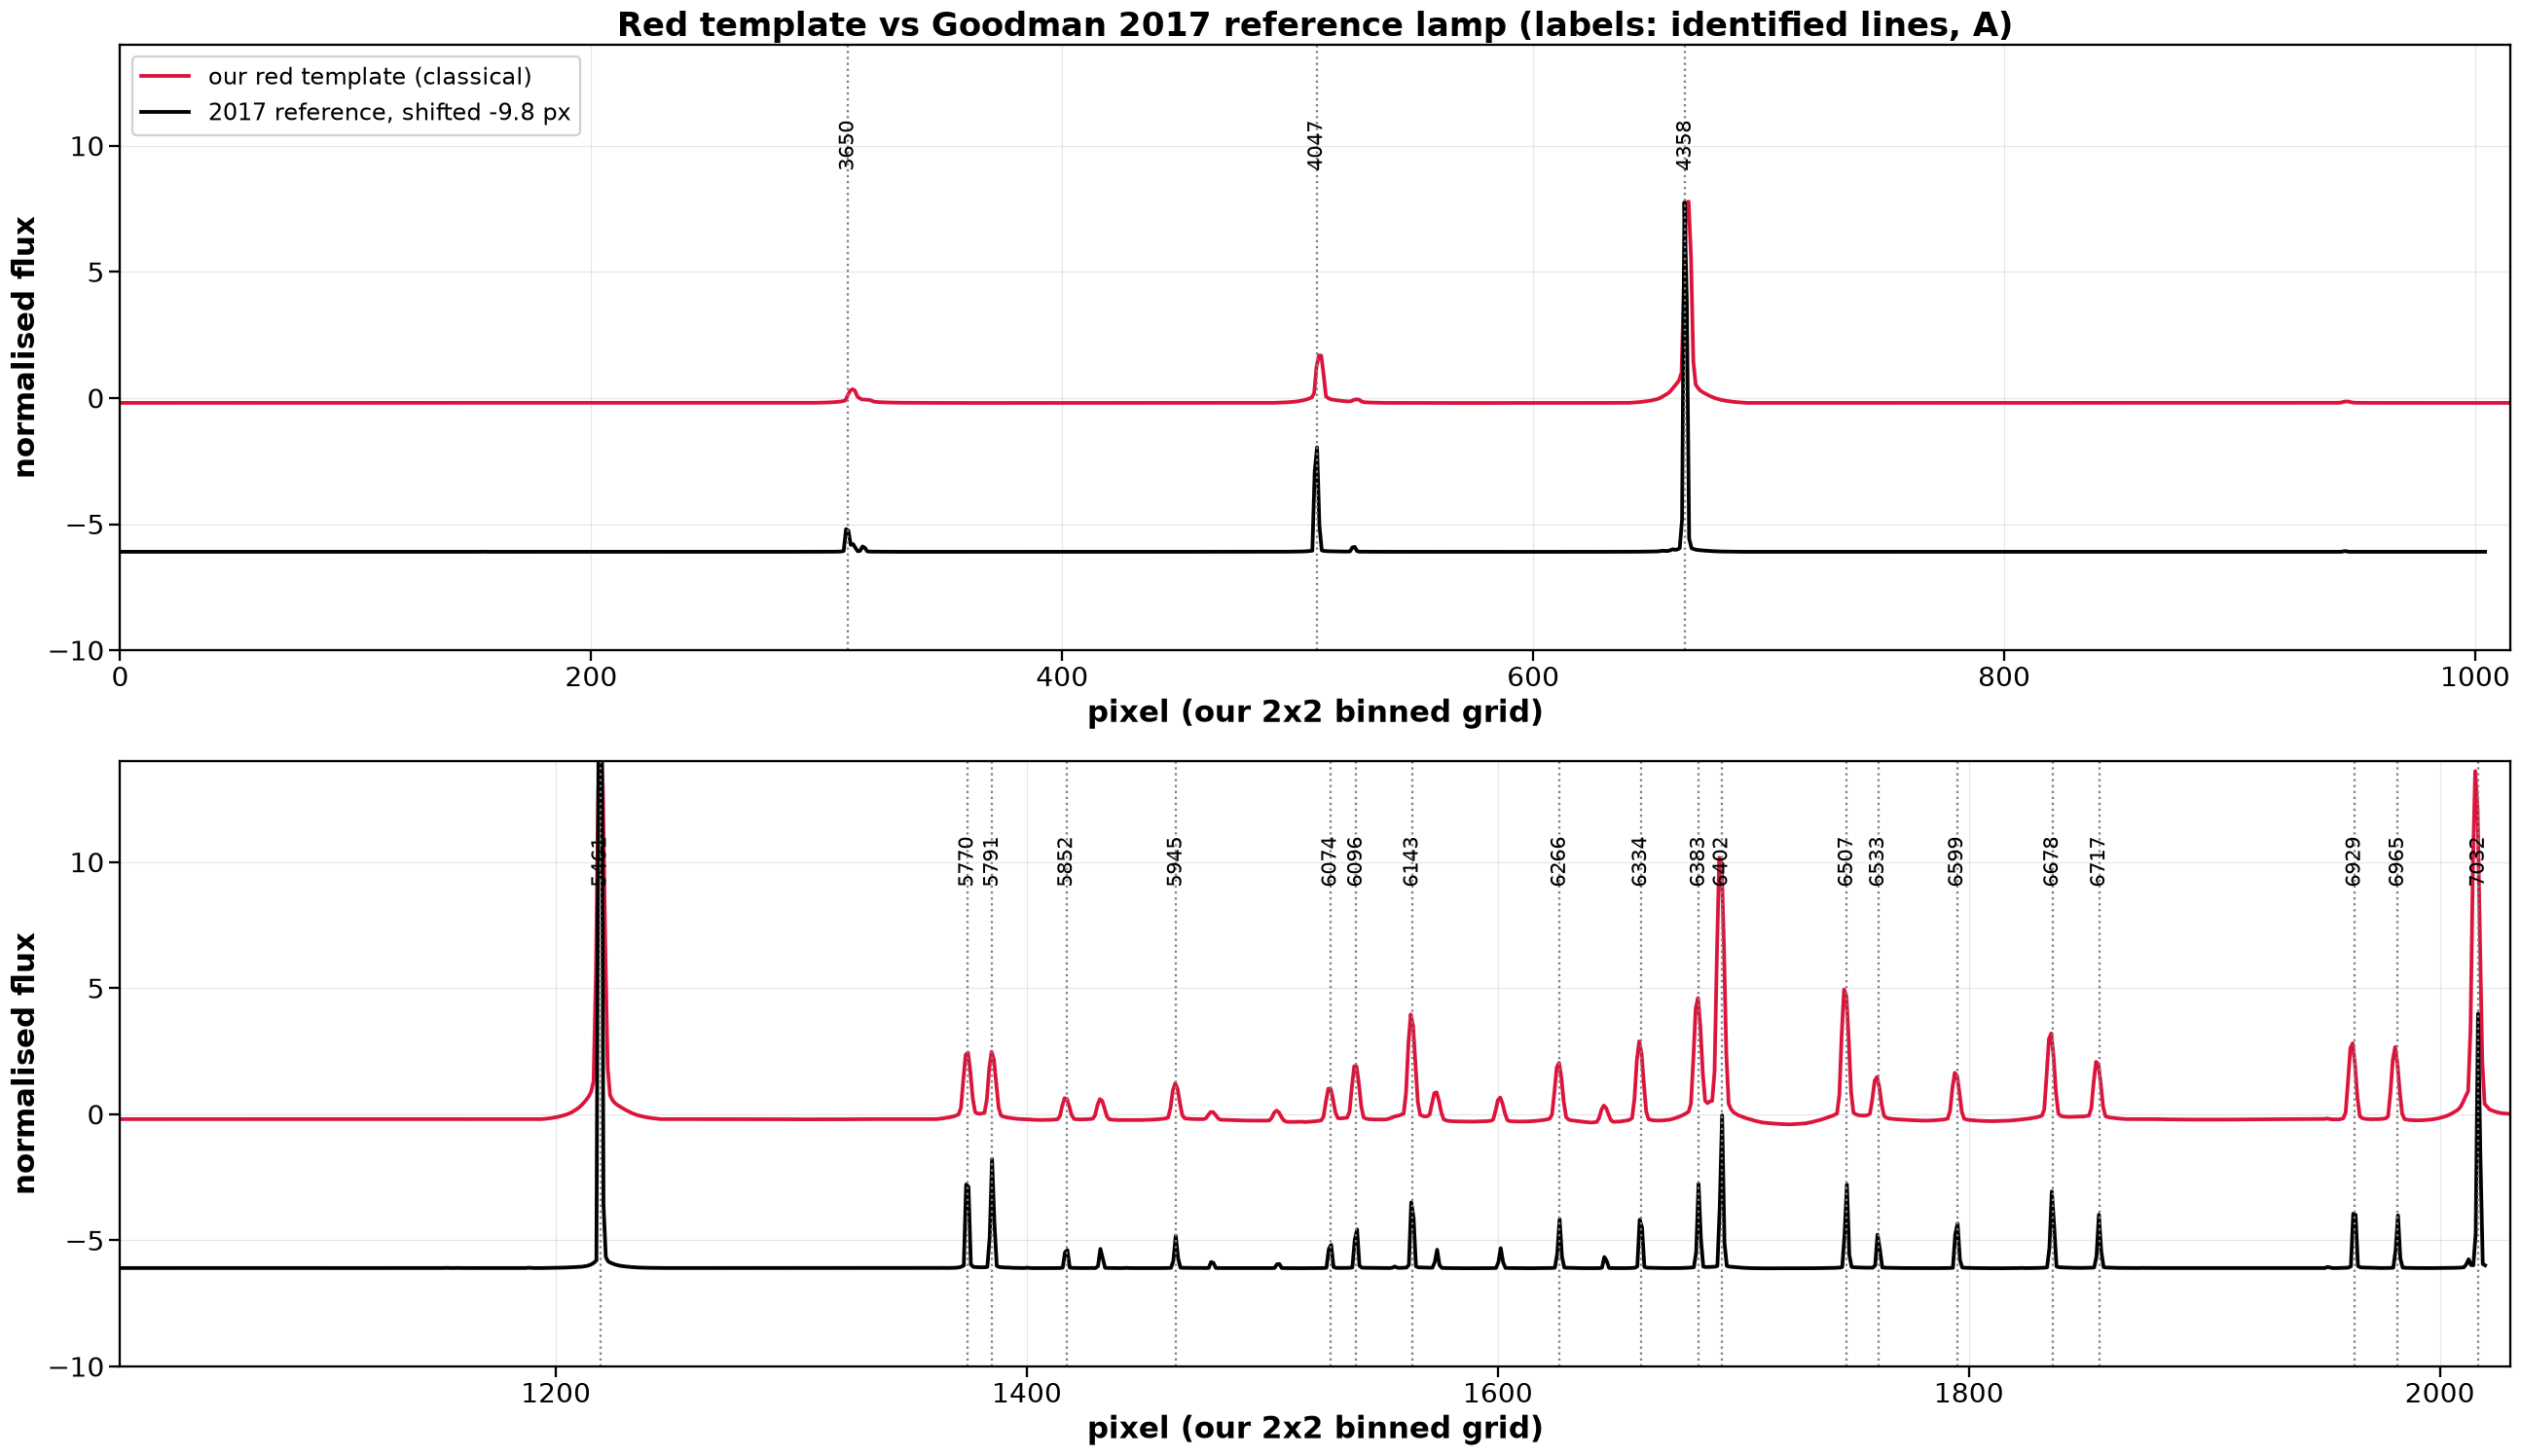

In [28]:
ref_prep = prepare_for_xcorr(ref_flux_2x2)
T_red = templates["ghts_red"]
n = min(len(ref_prep), len(T_red))
off_ref, pc_ref = xcorr_shift(T_red[:n], ref_prep[:n], MAX_LAG)
off_segs = segment_shifts(T_red[:n], ref_prep[:n], off_ref)
print(f"Red template vs 2017 reference: offset = {off_ref:+.2f} px (binned), peak corr = {pc_ref:.3f}")
print(f"Per-segment offsets: {np.round(off_segs, 2)} px  -> "
      f"stretch {np.polyfit(SEG_CENTRES, off_segs, 1)[0] * 1000:+.2f} px per 1000 px")

# first wavelength solution for the red template: shift the reference solution by the measured offset
pix = np.arange(len(T_red))
wave_template_red = wsol_1x1(2 * (pix - off_ref) + 0.5)
print(f"Template wavelength range: {wave_template_red[0]:.1f} - {wave_template_red[-1]:.1f} A")
cam_pred = CAM_SENS * (11.600 - ref_hdr["CAM_ANG"])
print(f"Offset predicted from CAM_ANG difference alone ({11.600 - ref_hdr['CAM_ANG']:+.3f} deg): {cam_pred:+.1f} px")

fig, ax = plt.subplots(2, 1, figsize=(24, 14), sharey=True)
for a, (lo, hi) in zip(ax, [(0, n // 2), (n // 2, n)]):
    a.plot(pix[lo:hi], T_red[lo:hi], color="crimson", label="our red template (classical)")
    a.plot(pix[lo:hi] + off_ref, ref_prep[lo:hi] - 6, color="k", label=f"2017 reference, shifted {off_ref:+.1f} px")
    for _, r in ref_lines[(ref_lines.pix_2x2 + off_ref >= lo) & (ref_lines.pix_2x2 + off_ref < hi)].iterrows():
        a.axvline(r.pix_2x2 + off_ref, color="grey", ls=":", lw=1.5)
        a.text(r.pix_2x2 + off_ref, 9, f"{r.wavelength:.0f}",
               rotation=90, ha="center", va="bottom", fontsize=14)
    a.set(xlim=(lo, hi), ylim=(-10, 14), xlabel="pixel (our 2x2 binned grid)", ylabel="normalised flux")
ax[0].set_title("Red template vs Goodman 2017 reference lamp (labels: identified lines, A)")
ax[0].legend(loc="upper left")
plt.tight_layout()
plt.show()
